# تسک ۰۰۲ — آماده‌سازی داده

اینجا از شناخت داده به ساخت ورودی مدل‌ها می‌رسم. هدف اصلی‌ام همان فهرست مشتری‌های در معرض ریزش، درجهٔ خطر و اولویت پیگیری است. هر ۵۰ سؤال را نگه داشته‌ام و کنار کدها کوتاه توضیح می‌دهم چه کاری می‌کنم.

فروشگاه و نقش سازمانی، سناریوی آموزشی‌اند من با تیم واقعی شرکت جلسه نداشته‌ام. فایل تراکنش واقعیِ ورودی تمرین است، ولی اثر کمپین و سود حفظ مشتری را از آن نمی‌توانم ثابت کنم.

پنج روش هنوز انتخاب‌های اولیه‌اند. نوع روش‌ها از ایدهٔ خودم آمده و برای انتخاب الگوریتم مشخص از هوش مصنوعی هم مشورت گرفته‌ام. اینجا هیچ مدل پیش‌بینی آموزش نمی‌دهم، ولی برازش تبدیل‌ها هم بخشی از یادگیری از داده است و باید مرز آموزش را رعایت کند.

برای ساده و روشن ماندن ارزیابی، برچسب افت را با آستانهٔ ثابت نسبت به نرخ خرید خود مشتری می‌سازم از میانهٔ رفتار آیندهٔ کل مشتری‌ها استفاده نمی‌کنم. اثر فصل همچنان محدودیت است، نه مسئله‌ای که حل‌شده فرض کنم.

# قرارداد داده و ارزیابی

گذشتهٔ قابل‌استفاده از ۱ دسامبر ۲۰۱۰ تا قبل از ۱ سپتامبر ۲۰۱۱ است. رفتار بعدی از ۱ سپتامبر تا قبل از ۱۰ دسامبر بررسی می‌شود همهٔ رکوردهای موجود روز ۹ دسامبر داخل بازه‌اند، ولی خود روز آخر کامل نیست.

این جداسازی برای ساخت ویژگی و برچسب است، نه تقسیم آموزش و آزمون طبقه‌بند. برای این نسخهٔ تک‌زمان‌مرجع، مشتری‌های واجد شرایط را با بذر ثابت و نسبت تقریبی ۶۰/۲۰/۲۰ به آموزش، اعتبارسنجی و آزمون تقسیم می‌کنم. هر مشتری فقط در یک بخش است و نسبت برچسب تا حد ممکن حفظ می‌شود. این ارزیابی تعمیم بین مشتری‌ها در یک تاریخ است اعتبارسنجی واقعی روی زمان‌های آینده نیست. چون کل داده قبلاً اکتشاف شده، آزمون هم کاملاً دست‌نخورده از ابتدای پروژه نیست این محدودیت را گزارش می‌کنم و از اینجا به بعد برای تنظیم مدل از آن استفاده نمی‌کنم.

خطر را با PR-AUC، Precision@K، Recall@K، Lift@K و کالیبراسیون با baselineِ Recency و لجستیک مقایسه می‌کنم. خوشه‌ها با پروفایل، Silhouette و پایداری، قواعد با Support/Confidence/Lift و مدل خرید با خطای پیش‌بینی کنار baseline سنجیده می‌شوند. آستانهٔ عددی عمومی و اجباری نمی‌گذارم هدف‌های مشخص را روی آموزش و اعتبارسنجی، قبل از آزمون نهایی تعیین می‌کنم.

مشتری قابل‌امتیازدهی در ۱۲۰ روز آخر مشاهده خرید مثبت دارد این یک فرض قابل‌بررسی است. توقف خرید، نداشتن خرید در بازهٔ بعدی است. افت نرم برای مشتری دارای حداقل دو فاکتور مشاهده و خرید بعدی، کمترشدن نرخ تعداد یا مبلغ به زیر ۶۰٪ نرخ سابقهٔ خودش است. مدت سابقه از اولین خرید دیده‌شده حساب می‌شود و الزاماً تاریخ پیوستن واقعی نیست. نشانهٔ فاصله فقط با دست‌کم سه فاکتور و میانهٔ فاصلهٔ مثبت بررسی می‌شود.

`churn_target` ترکیب توقف، افت و فاصله است `soft_decline` فقط افت/فاصله در مشتریِ دارای خرید بعدی است. ستون‌های برچسب هرگز ویژگی نیستند. سقف‌ها، میانه‌ها، مقیاس‌ها و انتخاب ویژگی تجربی در ارزیابی باید فقط روی آموزش برازش شوند. خروجی مقیاس‌شدهٔ کل مشتری‌ها فقط نمای اکتشافی است. اثر واقعی حفظ مشتری به آزمایش جدا نیاز دارد.

## آماده‌کردن محیط

اینجا فایل، مسیر خروجی و تعریف بازه‌ها را مشخص می‌کنم. پارامترها فرض اولیهٔ ثبت‌شده‌اند و تحلیل حساسیت جای گزارش شفاف تغییر آن‌ها را نمی‌گیرد.

اینجا مسیرها و بازه‌ها را تعریف می‌کنم و دادهٔ خام را می‌خوانم.


In [1]:
%matplotlib inline

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Resolve paths within the cloned repository, without machine-specific folders.
PROJECT_ROOT = None
for directory in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
    for candidate in (directory, directory / "onlineshop-tasks"):
        if (candidate / "task-002").is_dir() and (candidate / "Online Retail.xlsx").is_file():
            PROJECT_ROOT = candidate
            break
    if PROJECT_ROOT is not None:
        break
if PROJECT_ROOT is None:
    raise FileNotFoundError("Keep Online Retail.xlsx in the repository root beside task-002; start the kernel within the project or its parent workspace.")
DATA_PATH = PROJECT_ROOT / "Online Retail.xlsx"
OUT_DIR = PROJECT_ROOT / "task-002" / "outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)

OBS_START = pd.Timestamp("2010-12-01 00:00:00")
OBS_CUTOFF = pd.Timestamp("2011-09-01")
OBS_END = OBS_CUTOFF - pd.Timedelta(nanoseconds=1)
PERF_START = pd.Timestamp("2011-09-01 00:00:00")
PERF_STOP = pd.Timestamp("2011-12-10")
PERF_END = PERF_STOP - pd.Timedelta(nanoseconds=1)
OBS_DAYS = (OBS_END.normalize() - OBS_START.normalize()).days + 1
PERF_DAYS = (PERF_END.normalize() - PERF_START.normalize()).days + 1
PERF_RATIO = PERF_DAYS / OBS_DAYS

# پارامترهای تعریف برچسب (قفل‌شده پیش از مدل‌سازی)
LOOKBACK_DAYS = 120     # مشتری قابل‌امتیازدهی: دست‌کم یک خرید در ۱۲۰ روز آخر مشاهده
DECLINE_THRESHOLD = 0.60  # افت ۴۰ درصدی نسبت به الگوی مورد انتظار گروه
GAP_MULTIPLIER = 2.0    # فاصلهٔ خرید بیش از دو برابر میانهٔ خود مشتری

df_raw = pd.read_excel(DATA_PATH, sheet_name="Online Retail", engine="openpyxl")
print("data_path:", DATA_PATH)
print("raw_shape:", df_raw.shape)
print("raw_dates:", df_raw["InvoiceDate"].min(), "to", df_raw["InvoiceDate"].max())
print("observation_days:", OBS_DAYS, "performance_days:", PERF_DAYS, "ratio:", round(PERF_RATIO, 6))
print("lookback_days:", LOOKBACK_DAYS, "decline_threshold:", DECLINE_THRESHOLD, "gap_multiplier:", GAP_MULTIPLIER)

data_path: C:\Users\akbar\OneDrive\Desktop\finalprojectDir\onlineshop-tasks\Online Retail.xlsx
raw_shape: (541909, 8)
raw_dates: 2010-12-01 08:26:00 to 2011-12-09 12:50:00
observation_days: 274 performance_days: 100 ratio: 0.364964
lookback_days: 120 decline_threshold: 0.6 gap_multiplier: 2.0


فایل داده از مسیر پروژه خوانده شد و شکل خام آن ۵۴۱٬۹۰۹ سطر و ۸ ستون است. بازهٔ زمانی داده از ۱ دسامبر ۲۰۱۰ تا ۹ دسامبر ۲۰۱۱ است، پس هر دو پنجرهٔ مشاهده و عملکرد داخل داده جا می‌شوند.

طول پنجرهٔ مشاهده ۲۷۴ روز و پنجرهٔ عملکرد ۱۰۰ روز است و نسبت آن‌ها ۰٫۳۶۵ می‌شود. این نسبت را بعداً برای مقایسهٔ منصفانهٔ فراوانی و مبلغ عملکرد با مشاهده استفاده می‌کنم.

هیچ تغییری روی `df_raw` اعمال نشد. همهٔ مراحل بعدی روی کپی‌ها انجام می‌شود تا اگر تصمیمی عوض شد بتوانم به دادهٔ خام برگردم.

# بخش اول: انتخاب داده

در این بخش مشخص می‌کنم کدام ستون‌ها و کدام ویژگی‌های ساخته‌شده به هدف ریزش مربوط‌اند. انتخاب ویژگی در این پروژه یک‌بار برای همهٔ الگوریتم‌ها انجام نمی‌شود، چون هر مرحله به نمای متفاوتی نیاز دارد. پس یک پایهٔ تراکنشی مشترک نگه می‌دارم و انتخاب نهایی را در هر نما انجام می‌دهم.

## سوال ۱

کدام ستون‌ها و ویژگی‌ها بیشترین ارتباط را با ریزش مشتری دارند؟

اینجا ویژگی‌های نامزد را از منطق رفتار خرید انتخاب می‌کنم


In [2]:
churn_drivers = pd.DataFrame([
    ["Recency", "فاصلهٔ آخرین خرید تا پایان پنجرهٔ مشاهده", "سیگنال زمانی نامزد"],
    ["Frequency", "تعداد فاکتور معتبر در پنجرهٔ مشاهده", "رفتار خرید دوره‌ای را نشان می‌دهد"],
    ["Monetary", "مجموع ارزش خرید در پنجرهٔ مشاهده", "شدت رابطهٔ اقتصادی را می‌سنجد"],
    ["Product variety", "تعداد کد کالای متمایز", "عمق رابطه با سبد کالا را نشان می‌دهد"],
    ["Average gap", "فاصلهٔ متوسط بین فاکتورها", "آهنگ خرید را قابل مقایسه می‌کند"],
    ["Tenure", "فاصلهٔ اولین خرید تا پایان مشاهده", "طول عمر مشتری است"],
    ["Basket value", "میانگین ارزش هر فاکتور", "قدرت سبد را جدا از فراوانی می‌سنجد"],
    ["Cancellation rate", "سهم فاکتورهای لغوشده", "ممکن است با تفاوت رفتار همراه باشد"],
    ["Return rate", "سهم خطوط برگشتی", "کیفیت رابطه را به چالش می‌کشد"],
], columns=["Driver", "Definition", "Why it matters"])
churn_drivers

,Driver,Definition,Why it matters
0,Recency,فاصلهٔ آخرین خرید تا پایان پنجرهٔ مشاهده,سیگنال زمانی نامزد
1,Frequency,تعداد فاکتور معتبر در پنجرهٔ مشاهده,رفتار خرید دوره‌ای را نشان می‌دهد
2,Monetary,مجموع ارزش خرید در پنجرهٔ مشاهده,شدت رابطهٔ اقتصادی را می‌سنجد
3,Product variety,تعداد کد کالای متمایز,عمق رابطه با سبد کالا را نشان می‌دهد
4,Average gap,فاصلهٔ متوسط بین فاکتورها,آهنگ خرید را قابل مقایسه می‌کند
5,Tenure,فاصلهٔ اولین خرید تا پایان مشاهده,طول عمر مشتری است
6,Basket value,میانگین ارزش هر فاکتور,قدرت سبد را جدا از فراوانی می‌سنجد
7,Cancellation rate,سهم فاکتورهای لغوشده,ممکن است با تفاوت رفتار همراه باشد
8,Return rate,سهم خطوط برگشتی,کیفیت رابطه را به چالش می‌کشد


اینجا ویژگی‌های نامزد را از منطق رفتار خرید انتخاب می‌کنم. تازگی، تعداد، مبلغ، تنوع و سابقه می‌توانند مفید باشند، ولی هنوز قوی‌ترین بودن هیچ‌کدام را ثابت نکرده‌ام. لغو و مرجوعی هم لزوماً نارضایتی نیستند.

## سوال ۲

جدول اهمیت ویژگی‌ها را از دید کسب‌وکار و داده بسازید.

اینجا اهمیت ستون برای کسب‌وکار را از نقش آن در مدل جدا می‌کنم


In [3]:
feature_importance = pd.DataFrame([
    ["CustomerID", "شناسهٔ مشتری", "کلید اتصال، نه ویژگی مدل"],
    ["InvoiceNo", "شناسهٔ فاکتور", "کلید سبد و شمارش فراوانی"],
    ["InvoiceDate", "زمان خرید", "ستون اصلی ساخت پنجره‌ها"],
    ["Quantity", "حجم خرید", "ورودی ساخت ارزش و ناهنجاری"],
    ["UnitPrice", "قیمت واحد", "ورودی ساخت ارزش و ناهنجاری"],
    ["Country", "بازار مشتری", "ویژگی زمینه‌ای و منطقه‌ای"],
    ["Description", "نام کالا", "برای تفسیر قواعد انجمنی، نه مدل CART"],
    ["StockCode", "کد کالا", "کلید سبد و تنوع کالا"],
], columns=["Column", "Business importance", "Data role"])
feature_importance

,Column,Business importance,Data role
0,CustomerID,شناسهٔ مشتری,کلید اتصال، نه ویژگی مدل
1,InvoiceNo,شناسهٔ فاکتور,کلید سبد و شمارش فراوانی
2,InvoiceDate,زمان خرید,ستون اصلی ساخت پنجره‌ها
3,Quantity,حجم خرید,ورودی ساخت ارزش و ناهنجاری
4,UnitPrice,قیمت واحد,ورودی ساخت ارزش و ناهنجاری
5,Country,بازار مشتری,ویژگی زمینه‌ای و منطقه‌ای
6,Description,نام کالا,برای تفسیر قواعد انجمنی، نه مدل CART
7,StockCode,کد کالا,کلید سبد و تنوع کالا


اینجا اهمیت ستون برای کسب‌وکار را از نقش آن در مدل جدا می‌کنم. شناسه برای اتصال لازم است، اما عددش رفتار مشتری را توضیح نمی‌دهد. تاریخ هم برای مرزبندی گذشته و آینده ضروری است.

## سوال ۳

حداقل سه ویژگی را نام ببرید که احتمالاً برای مدل مفید نیستند.

شناسه‌ها و کد خام را ویژگی پیوسته نمی‌گیرم


In [4]:
not_useful = pd.DataFrame([
    ["InvoiceNo", "شناسهٔ یکتاست و الگوی عددی ندارد"],
    ["Description", "متن آزاد با املا و کاردینالیتی بالا"],
    ["CustomerID", "شناسه است و مقدار عددی آن معنا ندارد"],
    ["StockCode", "کد خام است فقط برای تنوع و قواعد سبد مفید است"],
], columns=["Feature", "Reason"])
not_useful

,Feature,Reason
0,InvoiceNo,شناسهٔ یکتاست و الگوی عددی ندارد
1,Description,متن آزاد با املا و کاردینالیتی بالا
2,CustomerID,شناسه است و مقدار عددی آن معنا ندارد
3,StockCode,کد خام است فقط برای تنوع و قواعد سبد مفید است


شناسه‌ها و کد خام را ویژگی پیوسته نمی‌گیرم. شرح کالا را برای توضیح محصول نگه می‌دارم و StockCode را برای سبد و تنوع استفاده می‌کنم کنارگذاشتن از مدل به معنی حذف از پایه نیست.

## سوال ۴

یک دیتاست با ستون‌های انتخاب‌شده بسازید.

هر هشت ستون را در یک کپی نگه می‌دارم، چون نیاز بخش‌ها متفاوت است


In [5]:
selected_columns = [
    "InvoiceNo", "StockCode", "Description", "Quantity",
    "InvoiceDate", "UnitPrice", "CustomerID", "Country",
]
selected_df = df_raw[selected_columns].copy()
print("selected_shape:", selected_df.shape)
selected_df.head()

selected_shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom


هر هشت ستون را در یک کپی نگه می‌دارم، چون نیاز بخش‌ها متفاوت است. انتخاب نهایی در نمای هر مدل انجام می‌شود و دادهٔ خام دست‌نخورده می‌ماند.

## سوال ۵

تعداد ویژگی‌ها را قبل و بعد از انتخاب مقایسه کنید.

تعداد ستون خام با تعداد ویژگی مدل یکی نیست


In [6]:
stage_plan = pd.DataFrame([
    ["Shared transaction base", 8],
    ["Isolation Forest view (customer level)", 8],
    ["K-Means view", 8],
    ["CART view", 11],
    ["Association view (global baskets)", 2],
    ["Association view (customer-linked baskets)", 3],
    ["CLV view", 4],
], columns=["Stage", "Planned feature count"])
print("raw_columns:", df_raw.shape[1])
print("selected_columns:", selected_df.shape[1])
stage_plan


raw_columns: 8
selected_columns: 8


,Stage,Planned feature count
0,Shared transaction base,8
1,Isolation Forest view (customer level),8
2,K-Means view,8
3,CART view,11
4,Association view (global baskets),2
5,Association view (customer-linked baskets),3
6,CLV view,4


تعداد ستون خام با تعداد ویژگی مدل یکی نیست. جدول بالا برنامهٔ اولیهٔ نماهاست شناسه، زمینه و برچسب هم باید از ورودی واقعی مدل جدا باشند.

# بخش دوم: پاک‌سازی داده

اینجا کیفیت داده را بررسی می‌کنم و تصمیم‌های پاک‌سازی را می‌گیرم. اصل من این است که دادهٔ خام را نگه دارم، یک نسخهٔ پاک‌شده بسازم و حذف یا اصلاح را فقط در نمای مناسب انجام دهم. حذف یک‌بارهٔ سطرهای مشکوک، اطلاعات پنج الگوریتم مختلف را از بین می‌برد.

## سوال ۶

در هر ستون چند مقدار گمشده وجود دارد؟

اینجا گمشده‌ها را می‌شمارم


In [7]:
selected_df.isna().sum().to_frame("null_count")

,null_count
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


اینجا گمشده‌ها را می‌شمارم. علت خالی‌بودن شناسه را از شمارش به‌تنهایی نمی‌فهمم و تصادفی یا ساختاری بودنش را قطعی فرض نمی‌کنم.

## سوال ۷

درصد داده‌های گمشدهٔ هر ستون چقدر است؟

اینجا درصد گمشده را می‌بینم


In [8]:
null_table = pd.DataFrame({
    "null_count": selected_df.isna().sum(),
    "null_percent": selected_df.isna().mean().mul(100).round(2),
})
null_table

,null_count,null_percent
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


اینجا درصد گمشده را می‌بینم. برای تحلیل فردی به شناسه نیاز دارم، ولی رکورد ناشناس می‌تواند در سبد عمومی باقی بماند. این تصمیم، پوشش تحلیل مشتری را محدود می‌کند.

## سوال ۸

حداقل سه روش برای برخورد با داده‌های گمشده پیشنهاد دهید.

برای شناسه از حذف در نمای فردی و نگه‌داشتن در نمای عمومی استفاده می‌کنم


In [9]:
missing_strategies = pd.DataFrame([
    ["حذف سطر", "برای نماهای مشتری‌محور که شناسه لازم است"],
    ["پرچم و نگه‌داشتن", "برای ناهنجاری و قواعد سبد خرید"],
    ["جایگزینی با برچسب", "فقط برای Description با مقدار UNKNOWN"],
    ["جایگزینی با میانه یا مد", "رد می‌شود، چون هویت مشتری را جعل می‌کند"],
], columns=["Strategy", "Decision context"])
missing_strategies

,Strategy,Decision context
0,حذف سطر,برای نماهای مشتری‌محور که شناسه لازم است
1,پرچم و نگه‌داشتن,برای ناهنجاری و قواعد سبد خرید
2,جایگزینی با برچسب,فقط برای Description با مقدار UNKNOWN
3,جایگزینی با میانه یا مد,رد می‌شود، چون هویت مشتری را جعل می‌کند


برای شناسه از حذف در نمای فردی و نگه‌داشتن در نمای عمومی استفاده می‌کنم. شرح خالی را علامت می‌زنم. پرکردن شناسه با میانه یا مد هویت جعلی می‌سازد و مناسب نیست.

## سوال ۹

یک روش را انتخاب و پیاده‌سازی کنید.

اینجا متن‌ها را یکدست و شناسه را به عدد صحیحِ قابل‌گمشدگی تبدیل می‌کنم


In [10]:
clean_df = selected_df.copy()
clean_df["LineID"] = clean_df.index.astype(int)   # کلید یکتای هر سطر خام
clean_df["InvoiceNo"] = clean_df["InvoiceNo"].astype(str).str.strip().str.upper()
clean_df["StockCode"] = clean_df["StockCode"].astype(str).str.strip().str.upper()
clean_df["Description"] = clean_df["Description"].fillna("UNKNOWN").astype(str).str.strip().str.upper()
clean_df["Country"] = clean_df["Country"].astype(str).str.strip().str.upper()
clean_df["CustomerID"] = pd.to_numeric(clean_df["CustomerID"], errors="coerce").astype("Int64")
clean_df["HasCustomer"] = clean_df["CustomerID"].notna()
clean_df["IsCancellation"] = clean_df["InvoiceNo"].astype(str).str.startswith("C")
clean_df["IsReturn"] = clean_df["Quantity"] < 0
clean_df.isna().sum().to_frame("null_count_after_cleaning")


,null_count_after_cleaning
InvoiceNo,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0
LineID,0
HasCustomer,0


اینجا متن‌ها را یکدست و شناسه را به عدد صحیحِ قابل‌گمشدگی تبدیل می‌کنم. UNKNOWN فقط جایگزین نام ناموجود است، نه بازیابی نام واقعی کالا.

## سوال ۱۰

رکوردهای تکراری را شناسایی کنید.

اینجا تکرار را بدون LineID می‌سنجم


In [11]:
# تکراری بودن روی همهٔ ستون‌های داده سنجیده می‌شود LineID فقط شناسهٔ سطر است و در مقایسه نمی‌آید.
dup_cols = [c for c in clean_df.columns if c != "LineID"]
duplicate_count = int(clean_df.duplicated(subset=dup_cols).sum())
print("duplicate_rows:", duplicate_count)
print("duplicate_percent:", round(duplicate_count / len(clean_df) * 100, 2))


duplicate_rows: 5268
duplicate_percent: 0.97


اینجا تکرار را بدون LineID می‌سنجم چون شناسهٔ ردیف همیشه متفاوت است. این تعریف بعد از یکدست‌سازی متن‌ها اعمال می‌شود.

## سوال ۱۱

نسخهٔ بدون رکورد تکراری بسازید.

ردیف‌های کاملاً یکسان را با فرض تکرار ثبت، یک بار نگه می‌دارم


In [12]:
dedup_df = clean_df.drop_duplicates(subset=dup_cols).copy()
print("clean_shape:", clean_df.shape)
print("dedup_shape:", dedup_df.shape)
print("removed_rows:", len(clean_df) - len(dedup_df))
print("LineID unique:", dedup_df["LineID"].is_unique)


clean_shape: (541909, 12)
dedup_shape: (536641, 12)
removed_rows: 5268
LineID unique: True


ردیف‌های کاملاً یکسان را با فرض تکرار ثبت، یک بار نگه می‌دارم. این یک تصمیم مستند پاک‌سازی است بدون اطلاعات عملیاتی نمی‌توانم ثابت کنم تمام موارد خطا بوده‌اند.

## سوال ۱۲

نقاط پرت را با Boxplot و IQR بررسی کنید.

اینجا با نمودار خام انتهاهای توزیع را می‌بینم


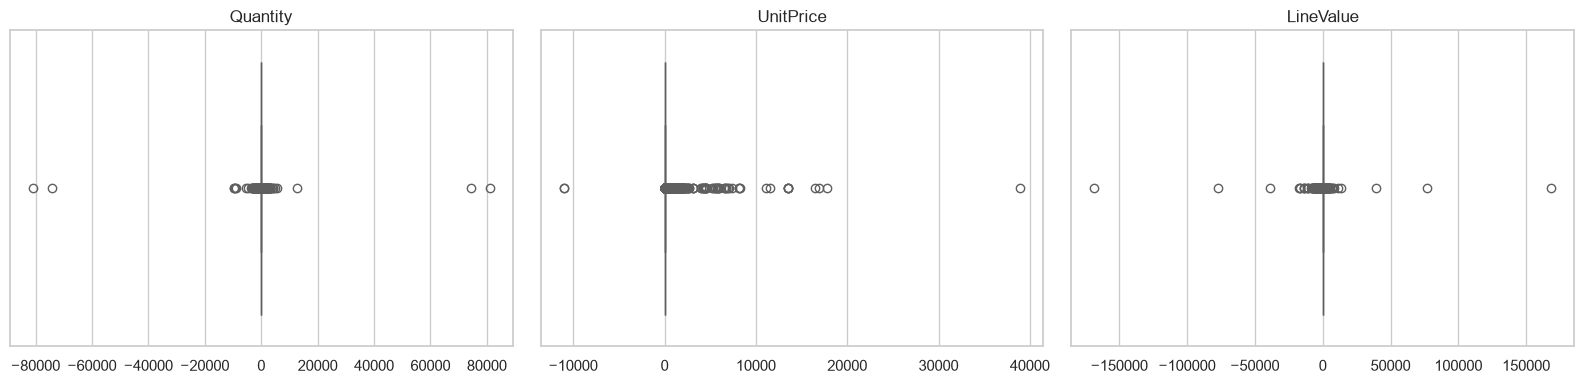

In [13]:
dedup_df["LineValue"] = dedup_df["Quantity"] * dedup_df["UnitPrice"]
outlier_numeric = ["Quantity", "UnitPrice", "LineValue"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, outlier_numeric):
    sns.boxplot(x=dedup_df[col], ax=ax, color="#7aa6c2")
    ax.set_title(col)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

اینجا با نمودار خام انتهاهای توزیع را می‌بینم. مقدار بزرگ صرفاً علامت بررسی است خرید عمده را خودکار حذف نمی‌کنم.

## سوال ۱۳

جدول تعداد نقاط پرت هر ویژگی را بسازید.

اینجا IQR را برای علامت‌زدن مقدار متفاوت استفاده می‌کنم


In [14]:
outlier_rows = []
for col in outlier_numeric:
    q1, q3 = dedup_df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (dedup_df[col] < lower) | (dedup_df[col] > upper)
    outlier_rows.append([col, int(mask.sum()), round(mask.mean() * 100, 2), round(lower, 2), round(upper, 2)])

pd.DataFrame(outlier_rows, columns=["Feature", "Outlier count", "Outlier percent", "Lower bound", "Upper bound"])

,Feature,Outlier count,Outlier percent,Lower bound,Upper bound
0,Quantity,58501,10.90,-12.50,23.50
1,UnitPrice,39450,7.35,-3.07,8.45
2,LineValue,45626,8.50,-16.72,37.88


اینجا IQR را برای علامت‌زدن مقدار متفاوت استفاده می‌کنم. درصد خارج محدوده، درصد خطای واقعی داده نیست.

## سوال ۱۴

حداقل سه روش برای برخورد با نقاط پرت پیشنهاد دهید.

حذف، سقف‌گذاری، پرچم‌گذاری و نگه‌داشتن خام گزینه‌های متفاوت‌اند


In [15]:
outlier_strategies = pd.DataFrame([
    ["حذف کامل", "اطلاعات خرید عمده و برگشت را از بین می‌برد"],
    ["Winsorization", "برای K-Means و ویژگی‌های شدیداً چوله"],
    ["پرچم‌گذاری", "برای Isolation Forest و تحلیل حساسیت"],
    ["نگه‌داشتن خام", "برای CART و CLV که تحمل بیشتری دارند"],
], columns=["Strategy", "Use case"])
outlier_strategies

,Strategy,Use case
0,حذف کامل,اطلاعات خرید عمده و برگشت را از بین می‌برد
1,Winsorization,برای K-Means و ویژگی‌های شدیداً چوله
2,پرچم‌گذاری,برای Isolation Forest و تحلیل حساسیت
3,نگه‌داشتن خام,برای CART و CLV که تحمل بیشتری دارند


حذف، سقف‌گذاری، پرچم‌گذاری و نگه‌داشتن خام گزینه‌های متفاوت‌اند. برای هر نما جدا تصمیم می‌گیرم تحمل مدل به مقدار افراطی به معنی بی‌اهمیت بودن خطای ثبت نیست.

## سوال ۱۵

یک روش را انتخاب و پیاده‌سازی کنید.

اینجا پرچم‌های توصیفی و قاعدهٔ اولیهٔ کد محصول را می‌سازم


In [16]:
for col in outlier_numeric:
    q1, q3 = dedup_df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    dedup_df[f"{col}_Outlier"] = ((dedup_df[col] < lower) | (dedup_df[col] > upper)).astype(int)

stock = dedup_df["StockCode"].astype(str)
numeric_code = stock.str.match(r"^\d{5}[A-Z]{0,2}$")
dcgs_code = stock.str.startswith("DCGS")
non_product = {"POST", "DOT", "M", "C2", "D", "S", "BANK CHARGES", "AMAZONFEE", "CRUK", "B", "PADS"}
dedup_df["IsProductCode"] = (
    (numeric_code | dcgs_code)
    & (~stock.isin(non_product))
    & (~stock.str.startswith("GIFT_"))
).astype(int)

print(dedup_df[["Quantity_Outlier", "UnitPrice_Outlier", "LineValue_Outlier"]].sum().to_string())
print("product_code_share:", round(dedup_df["IsProductCode"].mean(), 4))
print("rows:", len(dedup_df))

Quantity_Outlier     58501
UnitPrice_Outlier    39450
LineValue_Outlier    45626
product_code_share: 0.9945
rows: 536641


اینجا پرچم‌های توصیفی و قاعدهٔ اولیهٔ کد محصول را می‌سازم. قالب کد، محصول واقعی را تضمین نمی‌کند و موارد خارج قالب باید بازبینی شوند. پرچم IQR کل‌دوره فقط حسابرسی است و وارد ویژگی مدل نمی‌شود.

# بخش سوم: ساخت داده

اینجا ویژگی‌های مشتری‌محور را می‌سازم. واحد تحلیل از خط فاکتور به مشتری تغییر می‌کند و همهٔ ویژگی‌ها فقط از پنجرهٔ مشاهده می‌آیند. برچسب‌ها از پنجرهٔ عملکرد ساخته می‌شوند و هرگز به‌عنوان ویژگی استفاده نمی‌شوند.

## سوال ۱۶

گروه سابقهٔ مشتری را بسازید.

اینجا سابقه از اولین خرید دیده‌شده را گروه‌بندی می‌کنم


In [17]:
valid_sales = dedup_df[
    dedup_df["CustomerID"].notna()
    & (dedup_df["Quantity"] > 0)
    & (dedup_df["UnitPrice"] > 0)
    & (~dedup_df["InvoiceNo"].astype(str).str.startswith("C"))
    & (dedup_df["InvoiceDate"] >= OBS_START)
    & (dedup_df["InvoiceDate"] <= PERF_END)
].copy()

obs_sales = valid_sales[valid_sales["InvoiceDate"] <= OBS_END].copy()
perf_sales = valid_sales[valid_sales["InvoiceDate"] >= PERF_START].copy()

obs_customer = obs_sales.groupby("CustomerID").agg(
    Country=("Country", "first"),
    obs_invoices=("InvoiceNo", "nunique"),
    obs_spend=("LineValue", "sum"),
    obs_quantity=("Quantity", "sum"),
    obs_first=("InvoiceDate", "min"),
    obs_last=("InvoiceDate", "max"),
)
obs_customer["obs_tenure"] = (OBS_END - obs_customer["obs_first"]).dt.days
obs_customer["tenure_group"] = pd.cut(
    obs_customer["obs_tenure"],
    bins=[-1, 90, 180, 274],
    labels=["NEW", "DEVELOPING", "LOYAL"],
)

print("valid_sales:", valid_sales.shape)
print("obs_sales:", obs_sales.shape, "perf_sales:", perf_sales.shape)
print("obs_invoices:", obs_sales["InvoiceNo"].nunique(), "perf_invoices:", perf_sales["InvoiceNo"].nunique())
print("obs_customers:", obs_customer.shape[0], "perf_customers:", perf_sales["CustomerID"].nunique())
obs_customer["tenure_group"].value_counts().to_frame("customers")

valid_sales: (392692, 17)
obs_sales: (224036, 17) perf_sales: (168656, 17)
obs_invoices: 11413 perf_invoices: 7119
obs_customers: 3317 perf_customers: 2973


,customers
tenure_group,
LOYAL,1744
DEVELOPING,981
NEW,592


اینجا سابقه از اولین خرید دیده‌شده را گروه‌بندی می‌کنم این تاریخ الزاماً شروع واقعی رابطه نیست. اسم LOYAL در جدول فقط برچسب قدیمی گروه با سابقهٔ بیشتر است، نه اثبات وفاداری.

## سوال ۱۷

سطح ارزش خرید مشتری را بسازید.

اینجا مبلغ را برای گزارش به سه سطح تقسیم می‌کنم


In [18]:
monetary_edges = obs_customer["obs_spend"].quantile([1 / 3, 2 / 3]).tolist()
obs_customer["monetary_tier"] = pd.cut(
    obs_customer["obs_spend"],
    bins=[-np.inf, monetary_edges[0], monetary_edges[1], np.inf],
    labels=["LOW", "MID", "HIGH"],
)
print("monetary_edges:", [round(x, 2) for x in monetary_edges])
obs_customer["monetary_tier"].value_counts().to_frame("customers")

monetary_edges: [325.83, 950.33]


,customers
monetary_tier,
LOW,1106
HIGH,1106
MID,1105


اینجا مبلغ را برای گزارش به سه سطح تقسیم می‌کنم. این گروه‌ها خطر ریزش نیستند و آستانه‌های کل جامعه را به‌عنوان ویژگی ارزیابی وارد طبقه‌بند نمی‌کنم.

## سوال ۱۸

سطح تازگی مشتری را بسازید.

اینجا تازگی خرید را توصیفی گروه‌بندی می‌کنم


In [19]:
obs_customer["obs_recency"] = (OBS_END - obs_customer["obs_last"]).dt.days
obs_customer["recency_tier"] = pd.cut(
    obs_customer["obs_recency"],
    bins=[-1, 30, 90, 274],
    labels=["ACTIVE", "WARM", "COLD"],
)
obs_customer["recency_tier"].value_counts().to_frame("customers")

,customers
recency_tier,
COLD,1383
WARM,999
ACTIVE,935


اینجا تازگی خرید را توصیفی گروه‌بندی می‌کنم. این برچسب‌های گزارش با شرط دقیق ۱۲۰روزهٔ جامعهٔ مدل یکی نیستند.

## سوال ۱۹

حداقل دو ویژگی جدید با دلیل کسب‌وکاری بسازید.

اینجا ویژگی‌های گذشته و اطلاعات فقط‌برچسب را جدا می‌سازم


In [20]:
# ---------- ویژگی‌های مشاهده‌ای (فقط پنجرهٔ مشاهده) ----------
obs_customer["obs_avg_basket"] = obs_customer["obs_spend"] / obs_customer["obs_invoices"]
obs_customer["obs_avg_items"] = obs_customer["obs_quantity"] / obs_customer["obs_invoices"]
obs_customer["obs_avg_gap"] = np.where(
    obs_customer["obs_invoices"] > 1,
    (obs_customer["obs_last"] - obs_customer["obs_first"]).dt.days / (obs_customer["obs_invoices"] - 1),
    0.0,
)
obs_customer["is_one_time_obs"] = (obs_customer["obs_invoices"] == 1).astype(int)

obs_product_variety = obs_sales[obs_sales["IsProductCode"].eq(1)].groupby("CustomerID")["StockCode"].nunique()
obs_customer["obs_products"] = obs_customer.index.map(obs_product_variety).fillna(0).astype(int)

obs_all_customer = dedup_df[
    dedup_df["CustomerID"].notna() & (dedup_df["InvoiceDate"] <= OBS_END)
].copy()
cancel_invoices = obs_all_customer[obs_all_customer["IsCancellation"]].groupby("CustomerID")["InvoiceNo"].nunique()
obs_customer["cancel_invoices"] = obs_customer.index.map(cancel_invoices).fillna(0).astype(int)
obs_customer["cancel_rate"] = obs_customer["cancel_invoices"] / (obs_customer["obs_invoices"] + obs_customer["cancel_invoices"])

return_lines = obs_all_customer[obs_all_customer["Quantity"] < 0].groupby("CustomerID").size()
all_lines = obs_all_customer.groupby("CustomerID").size()
obs_customer["return_rate"] = (
    obs_customer.index.map(return_lines).fillna(0) / obs_customer.index.map(all_lines)
).astype(float)

# میانهٔ فاصلهٔ خرید خود مشتری فقط برای ساخت برچسب (پیشوند lbl_) و نه ویژگی
inv_obs = obs_sales.groupby(["CustomerID", "InvoiceNo"])["InvoiceDate"].min().reset_index()
inv_obs = inv_obs.sort_values(["CustomerID", "InvoiceDate"])
inv_obs["gap_days"] = inv_obs.groupby("CustomerID")["InvoiceDate"].diff().dt.days
obs_customer["lbl_median_gap_obs"] = obs_customer.index.map(inv_obs.groupby("CustomerID")["gap_days"].median())

# ---------- پنجرهٔ عملکرد (فقط برای برچسب) ----------
perf_customer = perf_sales.groupby("CustomerID").agg(
    perf_invoices=("InvoiceNo", "nunique"),
    perf_spend=("LineValue", "sum"),
    perf_quantity=("Quantity", "sum"),
    perf_products=("StockCode", "nunique"),
    perf_first=("InvoiceDate", "min"),
    perf_last=("InvoiceDate", "max"),
)

customer_df = obs_customer.join(perf_customer, how="left")
for col in ["perf_invoices", "perf_spend", "perf_quantity", "perf_products"]:
    customer_df[col] = customer_df[col].fillna(0)
customer_df = customer_df.reset_index()

# نرخ سابقه بر اساس زمان حضورِ دیده‌شده نه همهٔ ۲۷۴ روز برای تازه‌واردها.
customer_df["obs_exposure_days"] = (OBS_CUTOFF - customer_df["obs_first"].dt.normalize()).dt.days.clip(lower=1)
customer_df["perf_invoice_ratio"] = (customer_df["perf_invoices"] / PERF_DAYS) / (customer_df["obs_invoices"] / customer_df["obs_exposure_days"])
customer_df["perf_spend_ratio"] = (customer_df["perf_spend"] / PERF_DAYS) / (customer_df["obs_spend"] / customer_df["obs_exposure_days"])

# ---------- مشتری قابل‌امتیازدهی و ریزش سخت ----------
customer_df["eligible"] = (customer_df["obs_last"] >= OBS_CUTOFF - pd.Timedelta(days=LOOKBACK_DAYS)).astype(int)
customer_df["hard_churn"] = (customer_df["perf_invoices"] == 0).astype(int)

# ---------- ریزش نرم: افت نسبت به تغییر میانهٔ گروه (نرمال‌سازی فصلی) ----------
customer_df["decline_flag"] = (
    (customer_df["eligible"] == 1)
    & (customer_df["hard_churn"] == 0)
    & (customer_df["obs_invoices"] >= 2)
    & (
        (customer_df["perf_invoice_ratio"] < DECLINE_THRESHOLD)
        | (customer_df["perf_spend_ratio"] < DECLINE_THRESHOLD)
    )
).astype(int)

# ---------- سیگنال فاصله: مرجع پایان داده، میانهٔ فاصلهٔ خود مشتری ----------
last_any = customer_df[["obs_last", "perf_last"]].max(axis=1)
customer_df["lbl_days_since_last_at_end"] = (PERF_END - last_any).dt.days
customer_df["gap_signal"] = (
    (customer_df["eligible"] == 1)
    & (customer_df["obs_invoices"] >= 3)
    & (customer_df["lbl_median_gap_obs"] > 0)
    & (customer_df["lbl_days_since_last_at_end"] > GAP_MULTIPLIER * customer_df["lbl_median_gap_obs"])
).astype(int)

customer_df["churn_target_no_gap"] = ((customer_df["hard_churn"] == 1) | (customer_df["decline_flag"] == 1)).astype(int)
customer_df["churn_target"] = (
    (customer_df["hard_churn"] == 1) | (customer_df["decline_flag"] == 1) | (customer_df["gap_signal"] == 1)
).astype(int)

new_in_perf = perf_customer.index.difference(obs_customer.index)
eligible_df = customer_df[customer_df["eligible"] == 1]
print("customer_table:", customer_df.shape)
print("new_customers_first_seen_in_performance:", len(new_in_perf))
print("eligible:", len(eligible_df), "| dormant:", int((customer_df["eligible"] == 0).sum()))
print("Decline reference: fixed ratio to each customer observed daily rate; no future cohort median.")
print()
rates = pd.DataFrame({
    "all_obs_customers": [customer_df[c].sum() for c in ["hard_churn", "decline_flag", "gap_signal", "churn_target_no_gap", "churn_target"]],
    "eligible_customers": [eligible_df[c].sum() for c in ["hard_churn", "decline_flag", "gap_signal", "churn_target_no_gap", "churn_target"]],
}, index=["hard_churn", "decline_flag", "gap_signal", "churn_target_no_gap", "churn_target"])
rates["eligible_rate_percent"] = (rates["eligible_customers"] / len(eligible_df) * 100).round(2)
rates["all_rate_percent"] = (rates["all_obs_customers"] / len(customer_df) * 100).round(2)
rates

customer_df["soft_decline"] = ((customer_df["hard_churn"] == 0) & ((customer_df["decline_flag"] == 1) | (customer_df["gap_signal"] == 1))).astype(int)
# یک تقسیم مشتری‌محور ثابت نمونه‌های زمانی آینده در این نسخه ساخته نشده‌اند.
rng = np.random.default_rng(42)
customer_df["split"] = "dormant"
for label in (0, 1):
    ids = customer_df.index[(customer_df["eligible"] == 1) & (customer_df["churn_target"] == label)].to_numpy().copy()
    rng.shuffle(ids)
    a, b = int(.6 * len(ids)), int(.8 * len(ids))
    for indices, name in ((ids[:a], "train"), (ids[a:b], "validation"), (ids[b:], "test")):
        customer_df.loc[indices, "split"] = name
print("\nFixed customer split:")
print(customer_df.groupby("split")["churn_target"].agg(customers="size", target_rate="mean"))

customer_table: (3317, 37)
new_customers_first_seen_in_performance: 1021
eligible: 2298 | dormant: 1019
Decline reference: fixed ratio to each customer observed daily rate; no future cohort median.


Fixed customer split:
            customers  target_rate
split                             
dormant          1019         0.62
test              461         0.49
train            1378         0.49
validation        459         0.49


اینجا ویژگی‌های گذشته و اطلاعات فقط‌برچسب را جدا می‌سازم. افت با نرخ روزانه و مدت حضورِ دیده‌شده مقایسه می‌شود. مشتری تازه‌وارد سابقهٔ کوتاه و نامطمئن‌تری دارد فصل هم هنوز محدودیت است. صفرِ فاصلهٔ متوسط برای تک‌خریدی یک قرارداد همراه پرچم است، نه فاصلهٔ واقعی.

## سوال ۲۰

جدول ویژگی‌های جدید و دلیل کسب‌وکاری آن‌ها را بسازید.

جدول بالا نقش ستون‌ها را روشن می‌کند


In [21]:
new_features_table = pd.DataFrame([
    ["obs_avg_basket", "ویژگی", "میانگین ارزش هر فاکتور", "قدرت سبد را جدا از تعداد خرید نشان می‌دهد"],
    ["obs_avg_items", "ویژگی", "میانگین تعداد قلم در هر فاکتور", "حجم سبد را مستقل از ارزش می‌سنجد"],
    ["obs_avg_gap", "ویژگی", "فاصلهٔ متوسط بین فاکتورها", "آهنگ خرید را قابل مقایسه می‌کند"],
    ["obs_products", "ویژگی", "تعداد کالای متمایز", "عمق رابطه با سبد کالا را می‌سنجد"],
    ["cancel_rate", "ویژگی", "سهم فاکتورهای لغوشده", "نشانهٔ نوسان یا نارضایتی است"],
    ["return_rate", "ویژگی", "سهم خطوط برگشتی", "کیفیت رابطه را می‌سنجد"],
    ["is_one_time_obs", "ویژگی", "خرید فقط یک‌بار در مشاهده", "سابقهٔ محدود را مشخص می‌کند"],
    ["eligible", "فیلتر جامعه", "دست‌کم یک خرید در ۱۲۰ روز آخر مشاهده", "مشتری خفته را از مسئلهٔ پیشگیری جدا می‌کند"],
    ["perf_invoice_ratio", "فقط برچسب", "نسبت فراوانی عملکرد به انتظار", "افت عملکرد را استاندارد می‌کند"],
    ["perf_spend_ratio", "فقط برچسب", "نسبت مبلغ عملکرد به انتظار", "افت ارزش را استاندارد می‌کند"],
    ["lbl_median_gap_obs", "فقط برچسب", "میانهٔ فاصلهٔ خرید خود مشتری", "مبنای سیگنال فاصله"],
    ["gap_signal", "فقط برچسب", "فاصلهٔ تا پایان داده > ۲ × میانهٔ فاصله", "کندشدن آهنگ خرید را می‌گیرد"],
], columns=["Feature", "Role", "Definition", "Business reason"])
new_features_table

,Feature,Role,Definition,Business reason
0,obs_avg_basket,ویژگی,میانگین ارزش هر فاکتور,قدرت سبد را جدا از تعداد خرید نشان می‌دهد
1,obs_avg_items,ویژگی,میانگین تعداد قلم در هر فاکتور,حجم سبد را مستقل از ارزش می‌سنجد
2,obs_avg_gap,ویژگی,فاصلهٔ متوسط بین فاکتورها,آهنگ خرید را قابل مقایسه می‌کند
3,obs_products,ویژگی,تعداد کالای متمایز,عمق رابطه با سبد کالا را می‌سنجد
4,cancel_rate,ویژگی,سهم فاکتورهای لغوشده,نشانهٔ نوسان یا نارضایتی است
5,return_rate,ویژگی,سهم خطوط برگشتی,کیفیت رابطه را می‌سنجد
6,is_one_time_obs,ویژگی,خرید فقط یک‌بار در مشاهده,سابقهٔ محدود را مشخص می‌کند
7,eligible,فیلتر جامعه,دست‌کم یک خرید در ۱۲۰ روز آخر مشاهده,مشتری خفته را از مسئلهٔ پیشگیری جدا می‌کند
8,perf_invoice_ratio,فقط برچسب,نسبت فراوانی عملکرد به انتظار,افت عملکرد را استاندارد می‌کند
9,perf_spend_ratio,فقط برچسب,نسبت مبلغ عملکرد به انتظار,افت ارزش را استاندارد می‌کند


جدول بالا نقش ستون‌ها را روشن می‌کند. برچسب نهایی ترکیب توقف و افت/فاصله است اجزای آن در ورودی مدل قرار نمی‌گیرند. میانهٔ فاصله از گذشته می‌آید، ولی برای ساخت تعریف برچسب استفاده می‌شود.

## تحلیل تکمیلی الف: بررسی اولیه روی بخش توسعه

اینجا فقط مشتری‌های train و validation را برای بررسی ارتباط‌ها می‌بینم. این AUC توصیفی، نتیجهٔ آزمون نهایی مدل نیست.

اینجا ارتباط اولیه را فقط در توسعه بررسی می‌کنم.


In [22]:
def auc_rank(y, s):
    """AUC با آمارهٔ رتبه‌ای (Mann-Whitney)، بدون کتابخانهٔ یادگیری ماشین."""
    y = np.asarray(y)
    ranks = pd.Series(np.asarray(s, dtype=float)).rank().to_numpy()
    n1 = int(y.sum())
    n0 = len(y) - n1
    return (ranks[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

development = customer_df[customer_df["split"].isin(["train", "validation"])]
eligible_df = development
rows = []
for name, frame in [("development eligible customers", development)]:
    rows.append([name, len(frame), round(frame["hard_churn"].mean() * 100, 2), round(auc_rank(frame["hard_churn"], frame["obs_recency"]), 3)])
print(pd.DataFrame(rows, columns=["population", "customers", "hard_churn_percent", "AUC_of_recency_alone"]).to_string(index=False))

probe = eligible_df[["obs_recency", "obs_invoices", "obs_spend", "obs_products", "cancel_rate", "return_rate"]]
print("\ncorrelation with hard_churn (eligible only):")
print(pd.DataFrame({
    "pearson": probe.corrwith(eligible_df["hard_churn"]),
    "spearman": probe.corrwith(eligible_df["hard_churn"], method="spearman"),
}).round(3))

bins = pd.cut(eligible_df["obs_invoices"], [0, 2, 4, 1000], labels=["1-2 invoices", "3-4 invoices", "5+ invoices"])
print("\nhard churn by number of observation invoices (eligible only):")
print(eligible_df.groupby(bins, observed=True)["hard_churn"].agg(customers="size", churn_rate="mean").round(3))

                    population  customers  hard_churn_percent  AUC_of_recency_alone
development eligible customers       1837               31.14                  0.63

correlation with hard_churn (eligible only):
              pearson  spearman
obs_recency      0.21      0.20
obs_invoices    -0.22     -0.37
obs_spend       -0.12     -0.37
obs_products    -0.23     -0.33
cancel_rate     -0.12     -0.18
return_rate     -0.01     -0.19

hard churn by number of observation invoices (eligible only):
              customers  churn_rate
obs_invoices                       
1-2 invoices        868        0.46
3-4 invoices        465        0.27
5+ invoices         504        0.09


اینجا می‌بینم Recency و دیگر ویژگی‌ها در بخش توسعه چه رابطه‌ای با توقف خرید دارند. رابطهٔ آماری، علت ریزش یا اثر پیشنهاد را ثابت نمی‌کند و برای انتخاب نهایی باید ارزیابی جدا داشته باشم.

## تحلیل تکمیلی ب: حساسیت تعریف‌ها

اینجا فقط مشتری‌های مجاز بخش توسعه را با چند زمان مرجع و آستانه بررسی می‌کنم. تعریف نرخ، همان مقایسهٔ ثابت با سابقهٔ فرد است این جدول نسخهٔ بدون سیگنال فاصله را می‌سنجد.

اینجا حساسیت تعریف را روی زیرمجموعهٔ توسعه می‌سنجم.


In [23]:
development_ids = set(customer_df.loc[customer_df["split"].isin(["train", "validation"]), "CustomerID"])
development_sales = valid_sales[valid_sales["CustomerID"].isin(development_ids)]

def label_rates(cutoff, perf_days=100, lookback=120, decline_thr=DECLINE_THRESHOLD):
    cutoff = pd.Timestamp(cutoff)
    perf_end = min(cutoff + pd.Timedelta(days=perf_days) - pd.Timedelta(seconds=1), PERF_END)
    obs_days = (cutoff - OBS_START).days
    ratio = ((perf_end.normalize() - cutoff.normalize()).days + 1) / obs_days
    obs_ = development_sales[valid_sales["InvoiceDate"] < cutoff]
    perf_ = development_sales[(valid_sales["InvoiceDate"] >= cutoff) & (valid_sales["InvoiceDate"] <= perf_end)]
    oc = obs_.groupby("CustomerID").agg(inv=("InvoiceNo", "nunique"), spend=("LineValue", "sum"), first=("InvoiceDate", "min"), last=("InvoiceDate", "max"))
    pc = perf_.groupby("CustomerID").agg(pinv=("InvoiceNo", "nunique"), pspend=("LineValue", "sum"))
    t = oc.join(pc).fillna(0)
    el = t[t["last"] >= cutoff - pd.Timedelta(days=lookback)]
    hard = el["pinv"] == 0
    rep = el[(~hard) & (el["inv"] >= 2)]
    exposure = (cutoff - rep["first"].dt.normalize()).dt.days.clip(lower=1)
    duration = (perf_end.normalize() - cutoff.normalize()).days + 1
    inv_r = (rep["pinv"] / duration) / (rep["inv"] / exposure)
    sp_r = (rep["pspend"] / duration) / (rep["spend"] / exposure)
    decl = (inv_r < decline_thr) | (sp_r < decline_thr)
    return {
        "cutoff": str(cutoff.date()), "obs_days": obs_days, "lookback": lookback, "decline_thr": decline_thr,
        "customers": len(t), "eligible": len(el), "dormant": len(t) - len(el),
        "hard_churn_%": round(hard.mean() * 100, 1),
        "decline_%": round(decl.sum() / len(el) * 100, 1),
        "hard+decline_%": round((hard.sum() + decl.sum()) / len(el) * 100, 1),
    }

grid = [label_rates(cutoff, lookback=lb) for cutoff in ["2011-06-01", "2011-09-01"] for lb in (90, 120, 180)]
extra = [label_rates("2011-09-01", lookback=120, decline_thr=thr) for thr in (0.5, 0.7)]
sensitivity = pd.DataFrame(grid + extra)
sensitivity

C:\Users\akbar\AppData\Local\Temp\ipykernel_16148\470670357.py:9: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  obs_ = development_sales[valid_sales["InvoiceDate"] < cutoff]
C:\Users\akbar\AppData\Local\Temp\ipykernel_16148\470670357.py:10: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  perf_ = development_sales[(valid_sales["InvoiceDate"] >= cutoff) & (valid_sales["InvoiceDate"] <= perf_end)]
C:\Users\akbar\AppData\Local\Temp\ipykernel_16148\470670357.py:9: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  obs_ = development_sales[valid_sales["InvoiceDate"] < cutoff]
C:\Users\akbar\AppData\Local\Temp\ipykernel_16148\470670357.py:10: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  perf_ = development_sales[(valid_sales["InvoiceDate"] >= cutoff) & (valid_sales["InvoiceDate"] <= perf_end)]
C:\Users\akbar\AppData\Local\Temp\ipykernel_16148\470670357.py:9: UserWarning: B

C:\Users\akbar\AppData\Local\Temp\ipykernel_16148\470670357.py:9: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  obs_ = development_sales[valid_sales["InvoiceDate"] < cutoff]
C:\Users\akbar\AppData\Local\Temp\ipykernel_16148\470670357.py:10: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  perf_ = development_sales[(valid_sales["InvoiceDate"] >= cutoff) & (valid_sales["InvoiceDate"] <= perf_end)]
C:\Users\akbar\AppData\Local\Temp\ipykernel_16148\470670357.py:9: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  obs_ = development_sales[valid_sales["InvoiceDate"] < cutoff]
C:\Users\akbar\AppData\Local\Temp\ipykernel_16148\470670357.py:10: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  perf_ = development_sales[(valid_sales["InvoiceDate"] >= cutoff) & (valid_sales["InvoiceDate"] <= perf_end)]


C:\Users\akbar\AppData\Local\Temp\ipykernel_16148\470670357.py:9: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  obs_ = development_sales[valid_sales["InvoiceDate"] < cutoff]
C:\Users\akbar\AppData\Local\Temp\ipykernel_16148\470670357.py:10: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  perf_ = development_sales[(valid_sales["InvoiceDate"] >= cutoff) & (valid_sales["InvoiceDate"] <= perf_end)]
C:\Users\akbar\AppData\Local\Temp\ipykernel_16148\470670357.py:9: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  obs_ = development_sales[valid_sales["InvoiceDate"] < cutoff]
C:\Users\akbar\AppData\Local\Temp\ipykernel_16148\470670357.py:10: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  perf_ = development_sales[(valid_sales["InvoiceDate"] >= cutoff) & (valid_sales["InvoiceDate"] <= perf_end)]
C:\Users\akbar\AppData\Local\Temp\ipykernel_16148\470670357.py:9: UserWarning: B

C:\Users\akbar\AppData\Local\Temp\ipykernel_16148\470670357.py:10: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  perf_ = development_sales[(valid_sales["InvoiceDate"] >= cutoff) & (valid_sales["InvoiceDate"] <= perf_end)]


,cutoff,obs_days,lookback,decline_thr,customers,eligible,dormant,hard_churn_%,decline_%,hard+decline_%
0,2011-06-01,182,90,0.60,1354,1175,179,21.60,32.90,54.50
1,2011-06-01,182,120,0.60,1354,1244,110,20.40,31.80,52.30
2,2011-06-01,182,180,0.60,1354,1347,7,18.90,30.00,48.80
3,2011-09-01,274,90,0.60,1837,1545,292,28.30,19.00,47.20
4,2011-09-01,274,120,0.60,1837,1837,0,31.10,17.30,48.40
5,2011-09-01,274,180,0.60,1837,1837,0,31.10,17.30,48.40
6,2011-09-01,274,120,0.50,1837,1837,0,31.10,13.20,44.40
7,2011-09-01,274,120,0.70,1837,1837,0,31.10,21.30,52.50


تغییر نتیجه با آستانه یا نقطهٔ برش نشانهٔ حساسیت تعریف است. فصل، ترکیب مشتری و مدت سابقه همگی ممکن است دخیل باشند از این مقایسه اثر قطعی فصل نتیجه نمی‌گیرم. مجموعهٔ مشتری این بررسی به توسعهٔ زمان مرجع اصلی محدود است، پس نمایندهٔ کامل همهٔ مشتری‌های هر تاریخ نیست.

# بخش چهارم: یکپارچه‌سازی

اینجا یک نگاشت دستی کشور به منطقه می‌سازم تا اتصال جدول‌ها را تمرین کنم منبع خارجی واقعی دریافت نشده است.

## سوال ۲۱

یک جدول مرجع خارجی برای اتصال بسازید.

اینجا یک جدول مرجع دستی برای تمرین اتصال می‌سازم


In [24]:
europe = {
    "GERMANY", "FRANCE", "EIRE", "SPAIN", "NETHERLANDS", "BELGIUM", "SWITZERLAND",
    "PORTUGAL", "ITALY", "FINLAND", "NORWAY", "AUSTRIA", "CYPRUS", "DENMARK",
    "SWEDEN", "POLAND", "GREECE", "ICELAND", "MALTA", "LITHUANIA",
    "CZECH REPUBLIC", "EUROPEAN COMMUNITY", "CHANNEL ISLANDS",
}

def region_of(country):
    if country == "UNITED KINGDOM":
        return "DOMESTIC"
    if country in europe:
        return "EUROPE"
    return "OTHER"

region_map = pd.DataFrame({"Country": sorted(df_raw["Country"].dropna().astype(str).str.upper().unique())})
region_map["Region"] = region_map["Country"].map(region_of)
region_map.head(12)

,Country,Region
0,AUSTRALIA,OTHER
1,AUSTRIA,EUROPE
2,BAHRAIN,OTHER
3,BELGIUM,EUROPE
4,BRAZIL,OTHER
5,CANADA,OTHER
6,CHANNEL ISLANDS,EUROPE
7,CYPRUS,EUROPE
8,CZECH REPUBLIC,EUROPE
9,DENMARK,EUROPE


اینجا یک جدول مرجع دستی برای تمرین اتصال می‌سازم. این دادهٔ خارجیِ دریافت‌شده نیست نگاشت پیشنهادی کشور به منطقه است و طبقه‌بندی جغرافیایی آن باید متناسب با کاربرد بررسی شود.

## سوال ۲۲

کلید مشترک دو جدول را مشخص کنید.

کلید اتصال کشور است و کلید مشتری CustomerID می‌ماند


In [25]:
print("customer_key:", "CustomerID")
print("region_key:", "Country")
print("customer_countries:", customer_df["Country"].nunique())
print("region_countries:", region_map["Country"].nunique())

customer_key: CustomerID
region_key: Country
customer_countries: 36
region_countries: 38


کلید اتصال کشور است و کلید مشتری CustomerID می‌ماند. قبل از اتصال واقعی باید یکتایی نگاشت و چندکشوری‌بودن احتمالی هر شناسه بررسی شود فعلاً کشور اولین رکورد را گرفته‌ام.

## سوال ۲۳

جدول مشتری را با جدول مرجع ادغام کنید.

اینجا جدول منطقه را به مشتری وصل می‌کنم


In [26]:
customer_with_region = customer_df.merge(region_map, on="Country", how="left")
customer_with_region["Region"] = customer_with_region["Region"].fillna("OTHER")
print("rows:", len(customer_with_region))
print("null_region:", int(customer_with_region["Region"].isna().sum()))
customer_with_region["Region"].value_counts().to_frame("customers")

rows: 3317
null_region: 0


,customers
Region,
DOMESTIC,2989
EUROPE,295
OTHER,33


اینجا جدول منطقه را به مشتری وصل می‌کنم. تعداد ردیف نباید زیاد شود جدول مرجع باید برای هر کشور فقط یک ردیف داشته باشد.

## سوال ۲۴

انواع اتصال Inner، Left، Right و Outer را مقایسه کنید.

اینجا روی یک نمونهٔ ناقص از نگاشت، تفاوت اتصال‌ها را می‌بینم


In [27]:
top5_countries = customer_df["Country"].value_counts().head(5).index.tolist()
region_map_demo = region_map[region_map["Country"].isin(top5_countries)]

merge_rows = []
for how in ["inner", "left", "right", "outer"]:
    merged = customer_df[["CustomerID", "Country"]].merge(region_map_demo, on="Country", how=how)
    merge_rows.append([how, len(merged), int(merged["Region"].isna().sum())])

pd.DataFrame(merge_rows, columns=["How", "Rows", "Missing Region"])

,How,Rows,Missing Region
0,inner,3173,0
1,left,3317,144
2,right,3173,0
3,outer,3317,144


اینجا روی یک نمونهٔ ناقص از نگاشت، تفاوت اتصال‌ها را می‌بینم. این بخش آموزشی است و خروجی اتصال نمایشی، جای جدول اصلی را نمی‌گیرد.

## سوال ۲۵

نوع اتصال نهایی را انتخاب و پیاده‌سازی کنید.

Left Join را انتخاب می‌کنم تا مشتری به خاطر نبود نگاشت حذف نشود


In [28]:
customer_with_region = customer_df.merge(region_map, on="Country", how="left")
customer_with_region["Region"] = customer_with_region["Region"].fillna("OTHER")
region_dummies = pd.get_dummies(customer_with_region["Region"], prefix="region", dtype=int)
region_dummies = region_dummies.rename(columns=lambda c: c.lower())
customer_with_region = pd.concat([customer_with_region, region_dummies], axis=1)

print("rows_after_left_merge:", len(customer_with_region))
print("region_columns:", [c for c in customer_with_region.columns if c.startswith("region_")])
customer_with_region.filter(regex="^region_").sum().to_frame("customers")

rows_after_left_merge: 3317
region_columns: ['region_domestic', 'region_europe', 'region_other']


,customers
region_domestic,2989
region_europe,295
region_other,33


Left Join را انتخاب می‌کنم تا مشتری به خاطر نبود نگاشت حذف نشود. متغیرهای منطقه را می‌سازم، ولی شکل نهایی ورود کشور به مدل همچنان یک انتخاب اولیه است.

# بخش پنجم: قالب‌بندی داده

اینجا نوع داده‌ها، حافظه و متن‌ها را مرتب می‌کنم. قالب درست، هم خطای مدل‌سازی را کم می‌کند و هم حافظه را پایین می‌آورد. ولی تبدیل نوع نباید اطلاعات را تغییر دهد.

## سوال ۲۶

نوع دادهٔ هر ستون را بررسی کنید.

اینجا نوع ذخیره‌سازی را می‌خوانم


In [29]:
customer_with_region.dtypes.to_frame("dtype")

,dtype
CustomerID,Int64
Country,str
obs_invoices,int64
obs_spend,float64
obs_quantity,int64
obs_first,datetime64[us]
obs_last,datetime64[us]
obs_tenure,int64
tenure_group,category
monetary_tier,category


اینجا نوع ذخیره‌سازی را می‌خوانم. عددی بودن یک شناسه دلیل ورود آن به مدل نیست و ستون برچسب هم با وجود عددی بودن، ویژگی نیست.

## سوال ۲۷

کدام ستون‌ها باید به نوع دسته‌ای تبدیل شوند؟

ستون‌های گروه و منطقه برای گزارش دسته‌ای‌اند


In [30]:
categorical_candidates = ["Country", "Region", "tenure_group", "monetary_tier", "recency_tier"]
pd.DataFrame({"column": categorical_candidates, "reason": [
    "کشور بازار",
    "منطقهٔ جغرافیایی",
    "گروه سابقه",
    "گروه ارزش",
    "گروه تازگی",
]})

,column,reason
0,Country,کشور بازار
1,Region,منطقهٔ جغرافیایی
2,tenure_group,گروه سابقه
3,monetary_tier,گروه ارزش
4,recency_tier,گروه تازگی


ستون‌های گروه و منطقه برای گزارش دسته‌ای‌اند. تبدیل نوع فقط نحوهٔ ذخیره‌سازی است و معنی تحلیلی جدید ایجاد نمی‌کند.

## سوال ۲۸

نوع داده‌های مناسب را اعمال کنید.

اینجا نوع‌ها را روی یک نسخهٔ جدا اعمال می‌کنم


In [31]:
formatted_customer = customer_with_region.copy()
for col in categorical_candidates:
    formatted_customer[col] = formatted_customer[col].astype("category")
formatted_customer["CustomerID"] = formatted_customer["CustomerID"].astype("Int64")
formatted_customer.dtypes.to_frame("dtype_after")

,dtype_after
CustomerID,Int64
Country,category
obs_invoices,int64
obs_spend,float64
obs_quantity,int64
obs_first,datetime64[us]
obs_last,datetime64[us]
obs_tenure,int64
tenure_group,category
monetary_tier,category


اینجا نوع‌ها را روی یک نسخهٔ جدا اعمال می‌کنم. هنگام خواندن CSV ممکن است لازم باشد نوع‌ها دوباره تعیین شوند، چون CSV نوع category را حفظ نمی‌کند.

## سوال ۲۹

مصرف حافظه را قبل و بعد از تبدیل مقایسه کنید.

اینجا اثر category را روی حافظهٔ یک نسخهٔ آزمایشی می‌سنجم


In [32]:
def memory_mb(frame):
    return frame.memory_usage(deep=True).sum() / 1024 ** 2

raw_before = memory_mb(df_raw)
raw_after_frame = df_raw.copy()
for col in ["InvoiceNo", "StockCode", "Description", "Country"]:
    raw_after_frame[col] = raw_after_frame[col].astype("category")
raw_after = memory_mb(raw_after_frame)

pd.DataFrame({
    "stage": ["raw_before", "raw_after_category"],
    "memory_mb": [round(raw_before, 2), round(raw_after, 2)],
})

,stage,memory_mb
0,raw_before,126.18
1,raw_after_category,22.84


اینجا اثر category را روی حافظهٔ یک نسخهٔ آزمایشی می‌سنجم. کاهش حافظه لزوماً به معنی بهترشدن مدل یا سرعت تمام عملیات نیست.

## سوال ۳۰

ستون‌های متنی را استانداردسازی کنید.

اینجا بررسی می‌کنم فاصلهٔ اضافی متن‌ها حذف و کدها یکدست شده باشند


In [33]:
text_check = dedup_df[["InvoiceNo", "StockCode", "Description", "Country"]].astype(str)
print("leading_or_trailing_spaces:", int((text_check != text_check.apply(lambda s: s.str.strip())).sum().sum()))
print("stockcode_upper:", bool((dedup_df["StockCode"].astype(str) == dedup_df["StockCode"].astype(str).str.upper()).all()))
print("country_upper:", bool((dedup_df["Country"].astype(str) == dedup_df["Country"].astype(str).str.upper()).all()))
dedup_df[["InvoiceNo", "StockCode", "Description", "Country"]].head()

leading_or_trailing_spaces: 0
stockcode_upper: True


country_upper: True


,InvoiceNo,StockCode,Description,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,UNITED KINGDOM
1,536365,71053,WHITE METAL LANTERN,UNITED KINGDOM
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,UNITED KINGDOM
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,UNITED KINGDOM
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,UNITED KINGDOM


اینجا بررسی می‌کنم فاصلهٔ اضافی متن‌ها حذف و کدها یکدست شده باشند. این بررسی بازیابی شرح غلط یا هویت مشتری نیست.

# بخش ششم: کاهش داده

هدف این بخش کم کردن تکرار و نویز است، نه حذف اطلاعات مفید. دو معیار اصلی دارم: ویژگی‌های تقریباً ثابت و جفت‌های با همبستگی بالای ۰٫۸۵. هر حذف باید دلیل کسب‌وکاری یا آماری داشته باشد.

## سوال ۳۱

ویژگی‌های کم‌واریانس را شناسایی کنید.

اینجا ستون‌های تقریباً ثابت را برای شناخت بررسی می‌کنم


In [34]:
numeric_candidates = customer_with_region.select_dtypes(include=[np.number]).columns.tolist()
variance_rows = []
for col in numeric_candidates:
    values = customer_with_region[col]
    most_common = values.value_counts(normalize=True, dropna=False).iloc[0]
    variance_rows.append([col, values.nunique(dropna=False), round(most_common, 4), round(values.var(), 6)])

variance_table = pd.DataFrame(variance_rows, columns=["Feature", "Unique", "Most common share", "Variance"])
variance_table.sort_values("Most common share", ascending=False).head(12)

,Feature,Unique,Most common share,Variance
32,region_other,2,0.99,0.01
26,gap_signal,2,0.93,0.07
31,region_europe,2,0.91,0.08
30,region_domestic,2,0.90,0.09
24,decline_flag,2,0.89,0.10
29,soft_decline,2,0.88,0.11
22,eligible,2,0.69,0.21
12,cancel_rate,110,0.65,0.03
11,cancel_invoices,22,0.65,2.96
13,return_rate,555,0.65,0.00


اینجا ستون‌های تقریباً ثابت را برای شناخت بررسی می‌کنم. جدول شامل ستون‌های حسابرسی و برچسب هم هست از روی این جدول به‌تنهایی انتخاب ویژگی نهایی انجام نمی‌دهم.

## سوال ۳۲

ویژگی‌های با همبستگی بالا را پیدا کنید.

اینجا همبستگی ویژگی‌های نامزد را می‌بینم


In [35]:
corr_candidates = [
    "obs_invoices", "obs_spend", "obs_quantity", "obs_products",
    "obs_avg_basket", "obs_avg_items", "obs_avg_gap", "obs_tenure",
    "obs_recency", "cancel_rate", "return_rate", "is_one_time_obs", "region_europe",
]
corr = customer_with_region[corr_candidates].corr()

high_corr = []
for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        value = corr.iloc[i, j]
        if abs(value) >= 0.85:
            high_corr.append([corr.columns[i], corr.columns[j], round(value, 4)])

pd.DataFrame(high_corr, columns=["Feature 1", "Feature 2", "Correlation"])

,Feature 1,Feature 2,Correlation
0,obs_spend,obs_quantity,0.92
1,obs_avg_basket,obs_avg_items,0.97


اینجا همبستگی ویژگی‌های نامزد را می‌بینم. این تحلیل توصیفیِ گذشته است تصمیم تجربی نهایی برای ارزیابی باید در آموزش بازبینی شود.

## سوال ۳۳

نقشهٔ حرارتی همبستگی را رسم کنید.

اینجا همان رابطه‌ها را تصویری می‌بینم


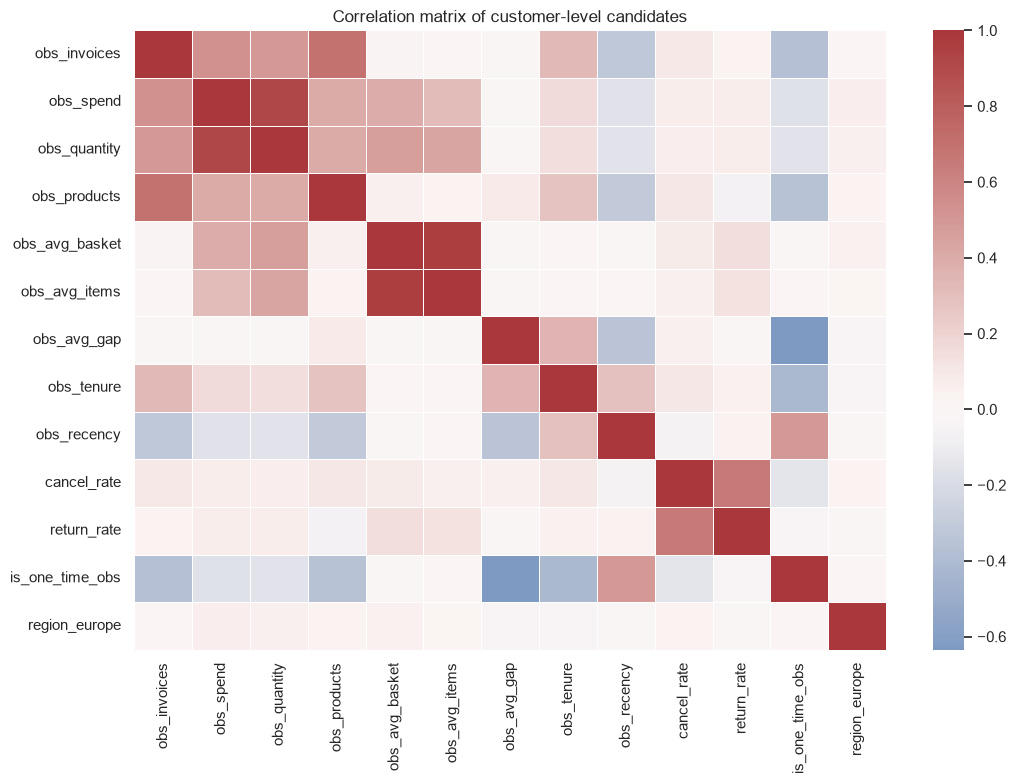

In [36]:
plt.figure(figsize=(11, 8))
sns.heatmap(corr, cmap="vlag", center=0, annot=False, linewidths=0.5)
plt.title("Correlation matrix of customer-level candidates")
plt.tight_layout()
plt.show()

اینجا همان رابطه‌ها را تصویری می‌بینم. همبستگی علت را ثابت نمی‌کند و برای درخت تصمیم الزام حذف یک ویژگی ایجاد نمی‌کند.

## سوال ۳۴

کدام ویژگی را حذف می‌کنید و چرا؟

اینجا چند ویژگی مشابه را برای ساده‌بودن نسخهٔ اولیه کنار می‌گذارم


In [37]:
drop_decisions = pd.DataFrame([
    ["obs_quantity", "همبستگی ۰٫۹۱۸ با obs_spend", "مبلغ خام کسب‌وکاری‌تر است"],
    ["obs_avg_items", "همبستگی ۰٫۹۶۸ با obs_avg_basket", "میانگین ارزش سبد گویاتر است"],
    ["region_domestic", "گروه مرجع و ۹۰٪ فراوانی", "با عرض از مبدأ و region_europe تکراری است"],
    ["region_other", "کمتر از ۱٪ فراوانی", "تقریباً ثابت است"],
    ["cancel_invoices", "همبستگی بالا با cancel_rate", "نرخ نسبت به تعداد خام گویاتر است"],
], columns=["Dropped", "Reason", "Kept alternative"])
drop_decisions

,Dropped,Reason,Kept alternative
0,obs_quantity,همبستگی ۰٫۹۱۸ با obs_spend,مبلغ خام کسب‌وکاری‌تر است
1,obs_avg_items,همبستگی ۰٫۹۶۸ با obs_avg_basket,میانگین ارزش سبد گویاتر است
2,region_domestic,گروه مرجع و ۹۰٪ فراوانی,با عرض از مبدأ و region_europe تکراری است
3,region_other,کمتر از ۱٪ فراوانی,تقریباً ثابت است
4,cancel_invoices,همبستگی بالا با cancel_rate,نرخ نسبت به تعداد خام گویاتر است


اینجا چند ویژگی مشابه را برای ساده‌بودن نسخهٔ اولیه کنار می‌گذارم. این انتخاب را قطعی یا اثبات‌شده نمی‌دانم مخصوصاً حذف منطقهٔ مرجع الزام CART نیست. در خوشه‌بندی باید مراقب وزن‌گرفتن چندبارهٔ یک جنبهٔ رفتار باشم.

## سوال ۳۵

دیتاست کاهش‌یافته را بسازید.

اینجا تاریخ‌ها و ستون‌های آینده/حسابرسی را از نمای کاهش‌یافته جدا می‌کنم


In [38]:
audit_drop = [
    "obs_quantity", "obs_avg_items", "region_domestic", "region_other",
    "cancel_invoices", "obs_first", "obs_last", "perf_first", "perf_last",
]
perf_drop = [c for c in customer_with_region.columns if c.startswith(("perf_", "expected_", "lbl_"))]
reduced_customer = customer_with_region.drop(columns=audit_drop + perf_drop).copy()

print("before_reduction:", customer_with_region.shape)
print("after_reduction:", reduced_customer.shape)
print("remaining_perf_columns:", [c for c in reduced_customer.columns if c.startswith(("perf_", "lbl_"))])
reduced_customer.dtypes.to_frame("dtype")


before_reduction: (3317, 43)
after_reduction: (3317, 26)
remaining_perf_columns: []


,dtype
CustomerID,Int64
Country,str
obs_invoices,int64
obs_spend,float64
obs_tenure,int64
tenure_group,category
monetary_tier,category
obs_recency,int64
recency_tier,category
obs_avg_basket,float64


اینجا تاریخ‌ها و ستون‌های آینده/حسابرسی را از نمای کاهش‌یافته جدا می‌کنم. معیار ورود مدل فهرست صریح ویژگی‌هاست فقط نداشتن پیشوند perf کافی نیست.

# بخش هفتم: تبدیل داده

در این بخش مقیاس‌ها را بررسی و دو روش Min-Max و Standardization را با NumPy پیاده می‌کنم. انتخاب نهایی به الگوریتم بستگی دارد: K-Means به مقیاس حساس است، ولی CART و Isolation Forest و CLV نه.

## سوال ۳۶

آیا ویژگی‌های عددی مقیاس‌های متفاوتی دارند؟

اینجا مقیاس ویژگی‌های مشتری را مقایسه می‌کنم


In [39]:
clustering_features = [
    "obs_invoices", "obs_spend", "obs_products", "obs_avg_basket",
    "obs_tenure", "obs_recency", "cancel_rate", "return_rate",
]
reduced_customer[clustering_features].describe().T[["min", "mean", "std", "50%", "max"]]


,min,mean,std,50%,max
obs_invoices,1.00,3.44,5.59,2.00,127.00
obs_spend,2.90,"1,575.97","5,974.01",552.80,"176,355.94"
obs_products,0.00,48.97,66.11,29.00,"1,188.00"
obs_avg_basket,2.90,399.43,"1,435.70",283.50,"77,183.60"
obs_tenure,0.00,175.75,77.86,184.00,273.00
obs_recency,0.00,92.14,76.69,72.00,273.00
cancel_rate,0.00,0.11,0.18,0.00,0.88
return_rate,0.00,0.03,0.07,0.00,0.94


اینجا مقیاس ویژگی‌های مشتری را مقایسه می‌کنم. برای فاصلهٔ K-Means اختلاف مقیاس مهم است، ولی برای همهٔ مدل‌ها استانداردسازی لازم نیست.

## سوال ۳۷

Min-Max Scaling را با NumPy پیاده‌سازی کنید.

اینجا Min-Max را با NumPy برای فهم روش پیاده می‌کنم


In [40]:
def minmax_numpy(frame, columns):
    values = frame[columns].to_numpy(dtype=float)
    mins = values.min(axis=0)
    maxs = values.max(axis=0)
    span = np.where(maxs - mins == 0, 1.0, maxs - mins)
    scaled = (values - mins) / span
    return pd.DataFrame(scaled, columns=columns, index=frame.index)

minmax_demo = minmax_numpy(reduced_customer, clustering_features)
minmax_demo.agg(["min", "max"]).T

,min,max
obs_invoices,0.00,1.00
obs_spend,0.00,1.00
obs_products,0.00,1.00
obs_avg_basket,0.00,1.00
obs_tenure,0.00,1.00
obs_recency,0.00,1.00
cancel_rate,0.00,1.00
return_rate,0.00,1.00


اینجا Min-Max را با NumPy برای فهم روش پیاده می‌کنم. این خروجی کل جامعه نمایشی است و نباید مستقیماً برای ارزیابی طبقه‌بند استفاده شود.

## سوال ۳۸

Standardization را با NumPy پیاده‌سازی کنید.

اینجا استانداردسازی را پیاده می‌کنم


In [41]:
def standardize_numpy(frame, columns):
    values = frame[columns].to_numpy(dtype=float)
    means = values.mean(axis=0)
    stds = values.std(axis=0, ddof=0)
    stds = np.where(stds == 0, 1.0, stds)
    scaled = (values - means) / stds
    return pd.DataFrame(scaled, columns=columns, index=frame.index)

standard_demo = standardize_numpy(reduced_customer, clustering_features)
standard_demo.agg(["mean", "std"]).T

,mean,std
obs_invoices,-0.00,1.00
obs_spend,-0.00,1.00
obs_products,-0.00,1.00
obs_avg_basket,0.00,1.00
obs_tenure,-0.00,1.00
obs_recency,0.00,1.00
cancel_rate,-0.00,1.00
return_rate,0.00,1.00


اینجا استانداردسازی را پیاده می‌کنم. جابه‌جایی مرکز و مقیاس، چولگی را از بین نمی‌برد و در ارزیابی، پارامترها باید فقط از آموزش بیایند.

## سوال ۳۹

هیستوگرام ویژگی‌ها را قبل و بعد از مقیاس‌دهی مقایسه کنید.

اینجا شکل قبل و بعد را مقایسه می‌کنم


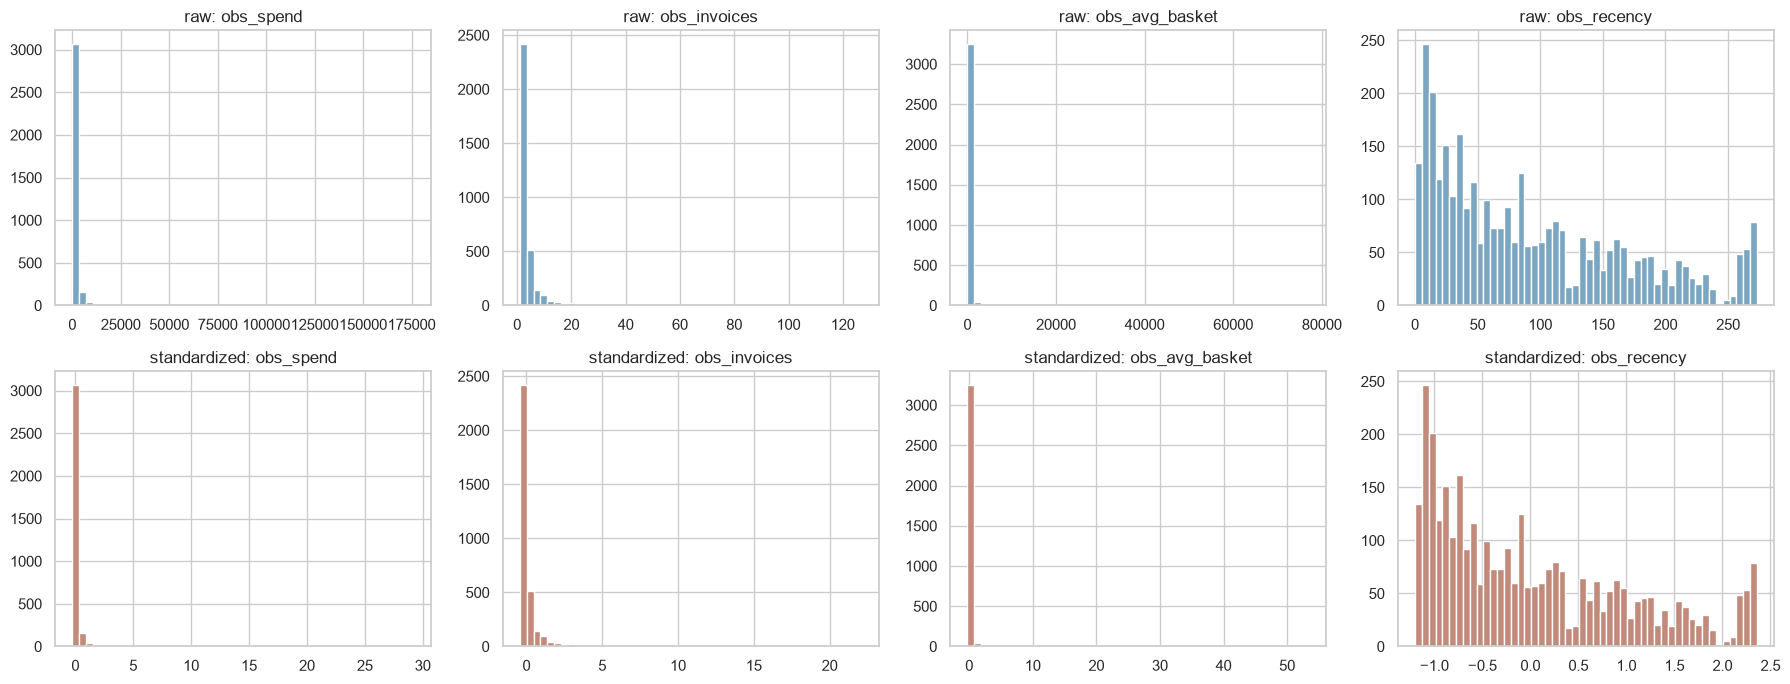

In [42]:
plot_cols = ["obs_spend", "obs_invoices", "obs_avg_basket", "obs_recency"]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for i, col in enumerate(plot_cols):
    axes[0, i].hist(reduced_customer[col], bins=50, color="#7aa6c2")
    axes[0, i].set_title(f"raw: {col}")
    axes[1, i].hist(standard_demo[col], bins=50, color="#c28a7a")
    axes[1, i].set_title(f"standardized: {col}")
plt.tight_layout()
plt.show()

اینجا شکل قبل و بعد را مقایسه می‌کنم. استانداردسازی شکل توزیع را عوض نمی‌کند تبدیل لگاریتمی هم گزینهٔ قابل‌مقایسه است، نه الزام همهٔ ستون‌ها.

## سوال ۴۰

دو روش را مقایسه و انتخاب نهایی را ثبت کنید.

برای نمایش اکتشافی K-Means، سقف صدک ۹۹، log1p و استانداردسازی را امتحان می‌کنم


In [43]:
winsor_columns = list(clustering_features)
clustering_raw = reduced_customer[clustering_features].astype(float).copy()
for col in winsor_columns:
    cap = clustering_raw[col].quantile(0.99)
    clustering_raw[col] = clustering_raw[col].clip(upper=cap)

clustering_log = clustering_raw.copy()
for col in winsor_columns:
    clustering_log[col] = np.log1p(clustering_log[col])

clustering_scaled = standardize_numpy(clustering_log, clustering_features)
clustering_scaled.insert(0, "CustomerID", reduced_customer["CustomerID"].values)

print("winsor_caps:", {col: round(float(clustering_raw[col].max()), 2) for col in winsor_columns})
print("scaled_mean:", round(float(clustering_scaled[clustering_features].mean().mean()), 6))
print("scaled_std:", round(float(clustering_scaled[clustering_features].std().mean()), 6))
print("max_abs_z:", round(float(clustering_scaled[clustering_features].abs().max().max()), 2))
clustering_scaled.head()


winsor_caps: {'obs_invoices': 22.84, 'obs_spend': 14344.04, 'obs_products': 271.68, 'obs_avg_basket': 2040.18, 'obs_tenure': 273.0, 'obs_recency': 272.0, 'cancel_rate': 0.6, 'return_rate': 0.34}
scaled_mean: 0.0
scaled_std: 1.000151
max_abs_z: 6.66


,CustomerID,obs_invoices,obs_spend,obs_products,obs_avg_basket,obs_tenure,obs_recency,cancel_rate,return_rate
0,12346,-0.88,2.67,-2.46,2.71,0.57,1.17,2.15,5.29
1,12347,0.95,1.30,0.98,0.97,0.79,-0.54,-0.65,-0.45
2,12348,0.27,0.77,-0.24,0.81,0.75,0.82,-0.65,-0.45
3,12350,-0.88,-0.48,-0.48,0.28,0.48,1.12,-0.65,-0.45
4,12352,0.95,0.81,-0.13,0.19,0.38,0.90,1.55,3.22


برای نمایش اکتشافی K-Means، سقف صدک ۹۹، log1p و استانداردسازی را امتحان می‌کنم. فایدهٔ این ترکیب هنوز نیاز به ارزیابی دارد. در هر ارزیابی سقف و مقیاس فقط با آموزش تعیین می‌شوند فایل خام مشتری مرجع بازسازی ورودی است. حساسیت به حذف نرخ لغو و برگشت را هم بعداً می‌سنجم.

# بخش هشتم: اعتبارسنجی دیتاست

اینجا همهٔ نماهای نهایی را می‌سازم، شکل و گمشدگی و تکرار و نوع داده را بررسی می‌کنم و مناسب‌بودن هر نما را برای الگوریتم هدفش می‌سنجم. در پایان فایل‌ها را ذخیره می‌کنم.

## سوال ۴۱

شکل نهایی دیتاست‌های آماده‌شده را بررسی کنید.

اینجا نماهای نهایی را می‌سازم و اندازه‌شان را از جدول همین اجرا می‌خوانم


In [44]:
# ---------- پایهٔ تراکنشی: هر سطر یک LineID یکتا دارد ----------
transactions_clean = dedup_df.copy()
transactions_clean["IsZeroPrice"] = (transactions_clean["UnitPrice"] == 0).astype(int)
transactions_clean["IsNegativePrice"] = (transactions_clean["UnitPrice"] < 0).astype(int)

# ---------- نمای ناهنجاری: سطح مشتری، فقط پنجرهٔ مشاهده ----------
returns_obs = obs_all_customer[obs_all_customer["Quantity"] < 0]
return_value_obs = (-(returns_obs["Quantity"] * returns_obs["UnitPrice"])).groupby(returns_obs["CustomerID"]).sum()
invoice_level = obs_sales.groupby(["CustomerID", "InvoiceNo"]).agg(
    InvoiceDate=("InvoiceDate", "min"),
    InvoiceValue=("LineValue", "sum"),
).reset_index()

anomaly_customers = obs_customer[["obs_invoices", "obs_spend", "obs_avg_basket", "obs_products", "cancel_rate"]].copy()
anomaly_customers["obs_max_line_qty"] = obs_sales.groupby("CustomerID")["Quantity"].max().reindex(anomaly_customers.index)
anomaly_customers["obs_max_invoice_value"] = invoice_level.groupby("CustomerID")["InvoiceValue"].max().reindex(anomaly_customers.index)
returns_value = return_value_obs.reindex(anomaly_customers.index).fillna(0)
anomaly_customers["return_value_share"] = returns_value / (returns_value + anomaly_customers["obs_spend"])
anomaly_feature_cols = [
    "obs_invoices", "obs_spend", "obs_avg_basket", "obs_products",
    "obs_max_line_qty", "obs_max_invoice_value", "return_value_share", "cancel_rate",
]
# قواعد ساده فقط خط پایه و حسابرسی‌اند برچسب حقیقت نیستند و در ارزیابی دایره‌ای استفاده نمی‌شوند.
anomaly_customers["rule_top1pct_spend"] = (anomaly_customers["obs_spend"] > anomaly_customers["obs_spend"].quantile(0.99)).astype(int)
anomaly_customers["rule_big_line_qty"] = (anomaly_customers["obs_max_line_qty"] >= 1000).astype(int)
anomaly_customers["rule_high_return_share"] = (anomaly_customers["return_value_share"] > 0.30).astype(int)
rule_cols = ["rule_top1pct_spend", "rule_big_line_qty", "rule_high_return_share"]
anomaly_customers["rule_any"] = anomaly_customers[rule_cols].max(axis=1)
anomaly_customers = anomaly_customers.reset_index()

# ---------- نمای سبد خرید: سراسری (همهٔ فاکتورها) و متصل به مشتری ----------
sales_all = dedup_df[
    (dedup_df["Quantity"] > 0) & (dedup_df["UnitPrice"] > 0) & (~dedup_df["IsCancellation"])
    & (dedup_df["IsProductCode"] == 1)
    & (dedup_df["InvoiceDate"] >= OBS_START) & (dedup_df["InvoiceDate"] <= PERF_END)
]
baskets_obs = sales_all[sales_all["InvoiceDate"] <= OBS_END][["InvoiceNo", "StockCode"]].drop_duplicates()
baskets_perf = sales_all[sales_all["InvoiceDate"] >= PERF_START][["InvoiceNo", "StockCode"]].drop_duplicates()

product_sales = valid_sales[valid_sales["IsProductCode"].eq(1)]
baskets_cust_obs = product_sales[product_sales["InvoiceDate"] <= OBS_END][["CustomerID", "InvoiceNo", "StockCode"]].drop_duplicates()
baskets_cust_perf = product_sales[product_sales["InvoiceDate"] >= PERF_START][["CustomerID", "InvoiceNo", "StockCode"]].drop_duplicates()

top_products = baskets_obs["StockCode"].value_counts().head(50).index
train_top = baskets_obs[baskets_obs["StockCode"].isin(top_products)]
test_top = baskets_perf[baskets_perf["StockCode"].isin(top_products)]
basket_matrix_train = pd.crosstab(train_top["InvoiceNo"], train_top["StockCode"]).reindex(index=pd.Index(baskets_obs["InvoiceNo"].unique(), name="InvoiceNo"), columns=top_products, fill_value=0).clip(upper=1)
basket_matrix_test = pd.crosstab(test_top["InvoiceNo"], test_top["StockCode"]).reindex(index=pd.Index(baskets_perf["InvoiceNo"].unique(), name="InvoiceNo"), columns=top_products, fill_value=0).clip(upper=1)

# ---------- نمای CLV ----------
# Для CLV خریدهای یک مشتری در یک روز را یک رویداد می‌گیرم.
daily = obs_sales.assign(purchase_day=obs_sales["InvoiceDate"].dt.normalize()).groupby(["CustomerID", "purchase_day"])["LineValue"].sum().reset_index()
daily = daily.sort_values(["CustomerID", "purchase_day"])
dg = daily.groupby("CustomerID")
ds = dg.agg(events=("purchase_day", "size"), first=("purchase_day", "min"), last=("purchase_day", "max"), total=("LineValue", "sum"))
first_values = dg["LineValue"].first().reindex(ds.index)
clv = pd.DataFrame({"CustomerID": ds.index})
clv["frequency"] = (ds["events"] - 1).to_numpy()
clv["recency"] = (ds["last"] - ds["first"]).dt.days.to_numpy()
clv["T"] = (OBS_CUTOFF - ds["first"]).dt.days.to_numpy()
repeat_money = (ds["total"] - first_values).to_numpy()
clv["monetary_value_repeat"] = np.divide(repeat_money, clv["frequency"].to_numpy(), out=np.zeros(len(clv)), where=clv["frequency"].to_numpy()>0)
clv["monetary_value_all"] = (ds["total"] / ds["events"]).to_numpy()
clv["is_repeat"] = (clv["frequency"] > 0).astype(int)

customer_lookup = customer_df.set_index("CustomerID")
clv["holdout_frequency"] = perf_sales.assign(purchase_day=perf_sales["InvoiceDate"].dt.normalize()).groupby("CustomerID")["purchase_day"].nunique().reindex(clv["CustomerID"]).fillna(0).values
clv["holdout_spend"] = customer_lookup["perf_spend"].reindex(clv["CustomerID"]).fillna(0).values

clv_calibration = clv[["CustomerID", "frequency", "recency", "T", "monetary_value_repeat", "monetary_value_all", "is_repeat"]].copy()
clv_holdout = clv[["CustomerID", "holdout_frequency", "holdout_spend"]].copy()
clv_gamma = clv_calibration[clv_calibration["frequency"] > 0].copy()

# ---------- نمای CART: فقط مشتریان قابل‌امتیازدهی مشتریان خفته جدا ----------
cart_feature_cols = [
    "obs_invoices", "obs_spend", "obs_products", "obs_avg_basket", "obs_avg_gap",
    "obs_tenure", "obs_recency", "cancel_rate", "return_rate", "is_one_time_obs",
    "region_europe",
]
cart_label_cols = ["hard_churn", "churn_target", "churn_target_no_gap", "decline_flag", "gap_signal", "soft_decline"]
cart_id_cols = ["CustomerID", "Country", "Region", "tenure_group", "monetary_tier", "recency_tier", "eligible", "split"]
eligible_mask = reduced_customer["eligible"].eq(1)
churn_model = reduced_customer.loc[eligible_mask, cart_id_cols + cart_feature_cols + cart_label_cols].copy()
dormant_customers = reduced_customer.loc[~eligible_mask, cart_id_cols + cart_feature_cols].copy()
dormant_customers["reactivated_in_performance"] = 1 - reduced_customer.loc[~eligible_mask, "hard_churn"].values

clustering_raw_full = reduced_customer[
    ["CustomerID", "Country", "Region", "tenure_group", "monetary_tier", "recency_tier"] + clustering_features
].copy()
online_retail_prepared = churn_model.copy()

datasets = {
    "transactions_clean": transactions_clean,
    "anomaly_customers": anomaly_customers,
    "clustering_customers": clustering_raw_full,
    "clustering_customers_scaled": clustering_scaled,
    "churn_customers": churn_model,
    "online_retail_prepared": online_retail_prepared,
    "cart_split_assignments": churn_model[["CustomerID", "split"]].copy(),
    "dormant_customers": dormant_customers,
    "baskets_train": baskets_obs,
    "baskets_test": baskets_perf,
    "baskets_customer_train": baskets_cust_obs,
    "baskets_customer_test": baskets_cust_perf,
    "basket_matrix_train": basket_matrix_train,
    "basket_matrix_test": basket_matrix_test,
    "clv_calibration": clv_calibration,
    "clv_holdout": clv_holdout,
    "clv_gamma_calibration": clv_gamma,
}
view_meta = {
    "cart_split_assignments": ("customer", "CustomerID"),
    "transactions_clean": ("transaction", "LineID"),
    "anomaly_customers": ("customer", "CustomerID"),
    "clustering_customers": ("customer", "CustomerID"),
    "clustering_customers_scaled": ("customer", "CustomerID"),
    "churn_customers": ("customer", "CustomerID"),
    "online_retail_prepared": ("customer", "CustomerID"),
    "dormant_customers": ("customer", "CustomerID"),
    "baskets_train": ("basket", "InvoiceNo + StockCode"),
    "baskets_test": ("basket", "InvoiceNo + StockCode"),
    "baskets_customer_train": ("basket", "CustomerID + InvoiceNo + StockCode"),
    "baskets_customer_test": ("basket", "CustomerID + InvoiceNo + StockCode"),
    "basket_matrix_train": ("basket", "InvoiceNo (index)"),
    "basket_matrix_test": ("basket", "InvoiceNo (index)"),
    "clv_calibration": ("customer", "CustomerID"),
    "clv_holdout": ("customer", "CustomerID"),
    "clv_gamma_calibration": ("customer", "CustomerID"),
}
summary = pd.DataFrame(
    [[name, frame.shape[0], frame.shape[1], *view_meta[name]] for name, frame in datasets.items()],
    columns=["Dataset", "Rows", "Columns", "Level", "Key"],
)
summary

# چند کنترل مستقیم روی ایرادهایی که اصلاح شدند.
assert len(basket_matrix_train) == baskets_obs["InvoiceNo"].nunique()
assert len(basket_matrix_test) == baskets_perf["InvoiceNo"].nunique()
assert np.allclose(basket_matrix_train.sum().to_numpy(), train_top.groupby("StockCode")["InvoiceNo"].nunique().reindex(top_products,fill_value=0).to_numpy())
assert (clv_calibration["recency"] <= clv_calibration["T"]).all()
assert (clv_calibration["T"] > 0).all()
assert not set(cart_feature_cols) & set(cart_label_cols)
assert churn_model["CustomerID"].is_unique
assert set(churn_model["split"]) == {"train", "validation", "test"}
print("Preparation checks passed: basket denominator, CLV time consistency, unique customer splits, feature/label separation.")

Preparation checks passed: basket denominator, CLV time consistency, unique customer splits, feature/label separation.


اینجا نماهای نهایی را می‌سازم و اندازه‌شان را از جدول همین اجرا می‌خوانم. ماتریس سبد همهٔ فاکتورهای واجد شرایط را نگه می‌دارد، حتی اگر برای ۵۰ محصول انتخابی تماماً صفر باشند. CLV بر اساس روز خرید است، ولی Frequency رفتاریِ CART همچنان تعداد فاکتور است.

## سوال ۴۲

آیا داده‌های گمشده باقی مانده است؟

اینجا گمشدهٔ هر نما را بررسی می‌کنم


In [45]:
null_rows = []
for name, frame in datasets.items():
    missing = int(frame.isna().sum().sum())
    if missing > 0:
        null_rows.append([name, missing, int((frame.isna().sum() > 0).sum())])

pd.DataFrame(null_rows, columns=["Dataset", "Missing cells", "Columns with missing"])

,Dataset,Missing cells,Columns with missing
0,transactions_clean,135037,1


اینجا گمشدهٔ هر نما را بررسی می‌کنم. شناسهٔ خالی در پایه و سبد عمومی عمدی است. صفرِ مبلغ تکراری برای فرد بدون تکرار، جایگزین سابقهٔ واقعی نیست و وارد برازش Gamma-Gamma نمی‌شود.

## سوال ۴۳

آیا رکورد تکراری باقی مانده است؟

اینجا یکتایی کلید هر نما و جدا بودن مشتری‌های جامعهٔ خطر و خفته را می‌سنجم


In [46]:
def n_dup(frame, subset):
    return int(frame.duplicated(subset=subset).sum())

duplicate_rows = [
    ["transactions_clean (LineID)", n_dup(transactions_clean, ["LineID"])],
    ["transactions_clean (all data columns)", n_dup(transactions_clean, [c for c in transactions_clean.columns if c != "LineID"])],
    ["transactions_clean (InvoiceNo+StockCode) - NOT a key", n_dup(transactions_clean, ["InvoiceNo", "StockCode"])],
    ["anomaly_customers", n_dup(anomaly_customers, ["CustomerID"])],
    ["clustering_customers", n_dup(clustering_raw_full, ["CustomerID"])],
    ["churn_customers", n_dup(churn_model, ["CustomerID"])],
    ["dormant_customers", n_dup(dormant_customers, ["CustomerID"])],
    ["baskets_train", n_dup(baskets_obs, ["InvoiceNo", "StockCode"])],
    ["baskets_test", n_dup(baskets_perf, ["InvoiceNo", "StockCode"])],
    ["baskets_customer_train", n_dup(baskets_cust_obs, ["CustomerID", "InvoiceNo", "StockCode"])],
    ["clv_calibration", n_dup(clv_calibration, ["CustomerID"])],
    ["customers shared by churn and dormant views", int(len(set(churn_model["CustomerID"]) & set(dormant_customers["CustomerID"])))],
]
pd.DataFrame(duplicate_rows, columns=["Check", "Count"])


,Check,Count
0,transactions_clean (LineID),0
1,transactions_clean (all data columns),0
2,transactions_clean (InvoiceNo+StockCode) - NOT...,5418
3,anomaly_customers,0
4,clustering_customers,0
5,churn_customers,0
6,dormant_customers,0
7,baskets_train,0
8,baskets_test,0
9,baskets_customer_train,0


اینجا یکتایی کلید هر نما و جدا بودن مشتری‌های جامعهٔ خطر و خفته را می‌سنجم. ترکیب فاکتور و کالا لزوماً کلید ردیف خام نیست.

## سوال ۴۴

آیا نقاط پرت مدیریت شده‌اند؟

پرت‌ها حذف نشده‌اند


In [47]:
outlier_check = pd.DataFrame({
    "Feature": ["Quantity", "UnitPrice", "LineValue"],
    "Flagged": [
        int(transactions_clean["Quantity_Outlier"].sum()),
        int(transactions_clean["UnitPrice_Outlier"].sum()),
        int(transactions_clean["LineValue_Outlier"].sum()),
    ],
    "Treatment": [
        "kept + flag",
        "kept + flag",
        "kept + flag; winsorized only for clustering",
    ],
})
outlier_check

,Feature,Flagged,Treatment
0,Quantity,58501,kept + flag
1,UnitPrice,39450,kept + flag
2,LineValue,45626,kept + flag; winsorized only for clustering


پرت‌ها حذف نشده‌اند سقف‌گذاری فقط در نسخهٔ نمایشی خوشه‌بندی است. لغو، مرجوعی و ردیف غیرمحصولی را باید با معنای خودشان بررسی کرد، نه اینکه همه خطا نامیده شوند.

## سوال ۴۵

آیا همهٔ ویژگی‌ها قالب درست دارند؟

اینجا عددی یا متنی بودن نماها را کنترل می‌کنم


In [48]:
format_check = pd.DataFrame({
    "Dataset": ["online_retail_prepared", "clustering_customers_scaled", "baskets_train", "clv_calibration"],
    "Non-numeric columns": [
        int(online_retail_prepared.select_dtypes(exclude=[np.number]).shape[1]),
        int(clustering_scaled.select_dtypes(exclude=[np.number]).shape[1]),
        int(baskets_obs.select_dtypes(exclude=[np.number]).shape[1]),
        int(clv_calibration.select_dtypes(exclude=[np.number]).shape[1]),
    ],
    "Numeric columns": [
        int(online_retail_prepared.select_dtypes(include=[np.number]).shape[1]),
        int(clustering_scaled.select_dtypes(include=[np.number]).shape[1]),
        int(baskets_obs.select_dtypes(include=[np.number]).shape[1]),
        int(clv_calibration.select_dtypes(include=[np.number]).shape[1]),
    ],
})
format_check

,Dataset,Non-numeric columns,Numeric columns
0,online_retail_prepared,6,19
1,clustering_customers_scaled,0,9
2,baskets_train,2,0
3,clv_calibration,0,7


اینجا عددی یا متنی بودن نماها را کنترل می‌کنم. در فایل CART ستون زمینه، split و برچسب هم هست مدل فقط باید cart_feature_cols را بگیرد.

## سوال ۴۶

آیا داده برای Isolation Forest مناسب است؟

نمای ناهنجاری در سطح مشتری و فقط از گذشته ساخته شده است


In [49]:
print("anomaly_customers:", anomaly_customers.shape)
print("nulls:", int(anomaly_customers.isna().sum().sum()))
print("feature_count:", len(anomaly_feature_cols))
print("rule flags (baseline only):")
print(anomaly_customers[rule_cols + ["rule_any"]].sum().to_string())
print("rule_any share:", round(float(anomaly_customers["rule_any"].mean()), 4))
print("share of valid-purchase revenue held by rule_any customers:", round(float(anomaly_customers.loc[anomaly_customers["rule_any"] == 1, "obs_spend"].sum() / anomaly_customers["obs_spend"].sum() * 100), 1), "%")
anomaly_customers[anomaly_feature_cols].describe().T[["min", "50%", "mean", "std", "max"]]


anomaly_customers: (3317, 13)
nulls: 0
feature_count: 8
rule flags (baseline only):
rule_top1pct_spend        34
rule_big_line_qty         35
rule_high_return_share    43
rule_any                  95
rule_any share: 0.0286
share of valid-purchase revenue held by rule_any customers: 32.3 %


,min,50%,mean,std,max
obs_invoices,1.00,2.00,3.44,5.59,127.00
obs_spend,2.90,552.80,"1,575.97","5,974.01","176,355.94"
obs_avg_basket,2.90,283.50,399.43,"1,435.70","77,183.60"
obs_products,0.00,29.00,48.97,66.11,"1,188.00"
obs_max_line_qty,1.00,36.00,100.86,"1,305.90","74,215.00"
obs_max_invoice_value,2.90,336.84,577.42,"1,831.12","77,183.60"
return_value_share,0.00,0.00,0.02,0.06,0.98
cancel_rate,0.00,0.00,0.11,0.18,0.88


نمای ناهنجاری در سطح مشتری و فقط از گذشته ساخته شده است. قواعد ساده خط پایهٔ حسابرسی‌اند، نه حقیقت زمینی. ردیف‌های غیرمحصولی هنوز می‌توانند در مبلغ خرید مثبت حضور داشته باشند و این محدودیت باید در تفسیر دیده شود.

## سوال ۴۷

آیا داده برای K-Means مناسب است؟

نمای عددی اکتشافی آماده است


In [50]:
print("clustering_scaled:", clustering_scaled.shape)
print("nulls:", int(clustering_scaled.isna().sum().sum()))
print("feature_count:", len(clustering_features))
print("mean_abs:", round(float(clustering_scaled[clustering_features].abs().mean().mean()), 6))
print("std_mean:", round(float(clustering_scaled[clustering_features].std().mean()), 6))
clustering_scaled[clustering_features].describe().T[["mean", "std", "min", "max"]]

clustering_scaled: (3317, 9)
nulls: 0
feature_count: 8
mean_abs: 0.771711
std_mean: 1.000151


,mean,std,min,max
obs_invoices,-0.00,1.00,-0.88,3.24
obs_spend,0.00,1.00,-4.22,2.67
obs_products,0.00,1.00,-3.10,2.08
obs_avg_basket,-0.00,1.00,-5.72,2.71
obs_tenure,0.00,1.00,-6.66,0.82
obs_recency,-0.00,1.00,-3.44,1.34
cancel_rate,0.00,1.00,-0.65,2.60
return_rate,-0.00,1.00,-0.45,5.29


نمای عددی اکتشافی آماده است، ولی انتخاب k، معنی گروه‌ها و پایداری هنوز انجام نشده. استانداردشدن به‌تنهایی مناسب‌بودن شکل خوشه‌ها را ثابت نمی‌کند. خفته‌ها در شناخت پرسونای کل مشتری‌ها باقی می‌مانند.

## سوال ۴۸

آیا داده برای CART مناسب است؟

نمای CART برچسب ترکیبی و split مشخص دارد


In [51]:
print("churn_model (eligible only):", churn_model.shape)
print("dormant_customers:", dormant_customers.shape)
print("feature_count:", len(cart_feature_cols))
print("label_columns:", cart_label_cols)
print("nulls:", int(churn_model.isna().sum().sum()))
print("hard_churn_rate:", round(churn_model["hard_churn"].mean(), 4))
print("churn_target_rate:", round(churn_model["churn_target"].mean(), 4))
print("churn_target_no_gap_rate:", round(churn_model["churn_target_no_gap"].mean(), 4))
print("dormant reactivated share:", round(float(dormant_customers["reactivated_in_performance"].mean()), 4))
churn_model[cart_feature_cols].describe().T[["min", "mean", "std", "max"]]


churn_model (eligible only): (2298, 25)
dormant_customers: (1019, 20)
feature_count: 11
label_columns: ['hard_churn', 'churn_target', 'churn_target_no_gap', 'decline_flag', 'gap_signal', 'soft_decline']
nulls: 0
hard_churn_rate: 0.3194
churn_target_rate: 0.4943
churn_target_no_gap_rate: 0.4839
dormant reactivated share: 0.3808


,min,mean,std,max
obs_invoices,1.00,4.33,6.45,127.00
obs_spend,2.90,"2,022.38","6,878.51","176,355.94"
obs_products,0.00,59.72,75.01,"1,188.00"
obs_avg_basket,2.90,396.23,518.75,"13,305.50"
obs_avg_gap,0.00,43.88,47.65,259.00
obs_tenure,0.00,161.74,84.45,273.00
obs_recency,0.00,48.01,34.82,119.00
cancel_rate,0.00,0.12,0.17,0.88
return_rate,0.00,0.02,0.06,0.67
is_one_time_obs,0.00,0.27,0.44,1.00


نمای CART برچسب ترکیبی و split مشخص دارد. train برای برازش، validation برای تنظیم و کالیبراسیون و test برای سنجش نهایی است. این تقسیم بین مشتری‌ها در یک زمان مرجع است، نه آزمون آینده. نرخ‌ها و تعدادهای تازه را از خروجی می‌خوانم و ویژگی آینده وارد فهرست ورودی نمی‌کنم.

## سوال ۴۹

آیا داده برای قواعد انجمنی و CLV مناسب است؟

سبد سراسری و متصل به مشتری جدا هستند


In [52]:
def basket_stats(frame, label):
    per_invoice = frame.groupby("InvoiceNo")["StockCode"].nunique()
    return [label, frame["InvoiceNo"].nunique(), frame["StockCode"].nunique(), round(float((per_invoice > 1).mean()), 4), float(per_invoice.median())]

basket_table = pd.DataFrame([
    basket_stats(baskets_obs, "global train (all invoices)"),
    basket_stats(baskets_cust_obs, "customer-linked train"),
    basket_stats(baskets_perf, "global test (all invoices)"),
    basket_stats(baskets_cust_perf, "customer-linked test"),
], columns=["view", "invoices", "products", "multi_item_share", "median_products"])
print(basket_table.to_string(index=False))
obs_invoice_count = baskets_obs["InvoiceNo"].nunique()
top_support = (
    baskets_obs.groupby("StockCode")["InvoiceNo"].nunique()
    .div(obs_invoice_count).mul(100).sort_values(ascending=False).head(10).round(2)
)
print("\ninvoices recovered by the global view (no CustomerID):", baskets_obs["InvoiceNo"].nunique() - baskets_cust_obs["InvoiceNo"].nunique())
print("matrix_train:", basket_matrix_train.shape, "matrix_test:", basket_matrix_test.shape)
print("clv_calibration:", clv_calibration.shape, "gamma_repeat:", clv_gamma.shape)
print("repeat_share:", round(float(clv_calibration["is_repeat"].mean()), 4))
print("holdout_zero_share:", round(float((clv_holdout["holdout_frequency"] == 0).mean()), 4))
print("monetary_repeat_median:", round(float(clv_gamma["monetary_value_repeat"].median()), 2))
top_support.to_frame("support_percent")


                       view  invoices  products  multi_item_share  median_products
global train (all invoices)     12383      3521              0.92            15.00
      customer-linked train     11342      3388              0.92            14.00
 global test (all invoices)      7390      3181              0.93            16.00
       customer-linked test      7060      3036              0.94            16.00

invoices recovered by the global view (no CustomerID): 1041
matrix_train: (12383, 50) matrix_test: (7390, 50)
clv_calibration: (3317, 7) gamma_repeat: (1890, 7)
repeat_share: 0.5698
holdout_zero_share: 0.4115
monetary_repeat_median: 305.47


,support_percent
StockCode,
85123A,12.87
22423,11.38
85099B,11.16
47566,10.72
20725,8.78
84879,7.45
21212,7.38
22720,7.25
22383,7.24


سبد سراسری و متصل به مشتری جدا هستند. انتخاب ۵۰ محصول فقط با گذشته انجام شده و مخرج support همهٔ سبدهای همان جامعه است. برای CLV خریدهای یک روز یک رویدادند و خرید تکراری یعنی روز خرید بعدی تک‌خریدی در BG/NBD می‌ماند ولی برازش Gamma-Gamma سابقهٔ تکراری مثبت می‌خواهد.

## سوال ۵۰

دیتاست‌های نهایی را ذخیره کنید و گزارش مدیریتی تهیه کنید.

اینجا نماها، فرهنگ ستون‌ها و قرارداد زمانی/برچسب را ذخیره می‌کنم تا ادامهٔ پروژه قابل‌تکرار باشد


In [53]:
for name, frame in datasets.items():
    frame.to_csv(OUT_DIR / f"{name}.csv", index=name.startswith("basket_matrix"))

summary.to_csv(OUT_DIR / "prepared_datasets_summary.csv", index=False)

feature_dictionary = pd.DataFrame([
    ["CustomerID", "id", "all customer datasets", "کلید مشتری"],
    ["LineID", "id", "transactions_clean", "کلید یکتای هر سطر خام"],
    ["Country", "context", "customer datasets", "کشور اصلی مشتری"],
    ["Region", "context", "customer datasets", "DOMESTIC/EUROPE/OTHER"],
    ["tenure_group", "context", "customer datasets", "گروه سابقه"],
    ["monetary_tier", "context", "customer datasets", "گروه ارزش"],
    ["recency_tier", "context", "customer datasets", "گروه تازگی"],
    ["eligible", "filter", "customer datasets", "خرید در ۱۲۰ روز آخر مشاهده جامعهٔ آموزش CART"],
    ["obs_invoices", "feature", "clustering + CART + anomaly", "فراوانی مشاهده"],
    ["obs_spend", "feature", "clustering + CART + anomaly", "مبلغ مشاهده"],
    ["obs_products", "feature", "clustering + CART + anomaly", "تنوع کالا"],
    ["obs_avg_basket", "feature", "clustering + CART + anomaly", "میانگین ارزش سبد"],
    ["obs_avg_gap", "feature", "CART", "فاصلهٔ متوسط خرید"],
    ["obs_tenure", "feature", "clustering + CART", "سابقهٔ مشاهده"],
    ["obs_recency", "feature", "clustering + CART", "فاصلهٔ آخرین خرید"],
    ["cancel_rate", "feature", "clustering + CART + anomaly", "نرخ لغو"],
    ["return_rate", "feature", "clustering + CART", "نرخ برگشت"],
    ["is_one_time_obs", "feature", "CART", "خرید یک‌باره"],
    ["region_europe", "feature", "CART", "مشتری اروپایی غیربریتانیا"],
    ["obs_max_line_qty", "feature", "anomaly", "بیشینهٔ تعداد در یک ردیف"],
    ["obs_max_invoice_value", "feature", "anomaly", "بیشینهٔ ارزش یک فاکتور"],
    ["return_value_share", "feature", "anomaly", "سهم ارزش برگشت از فعالیت ناخالص"],
    ["rule_*", "audit", "anomaly baseline", "قواعد ساده حقیقت زمینی نیستند"],
    ["hard_churn", "label", "CART", "ریزش سخت"],
    ["churn_target", "label", "CART", "برچسب نهایی ترکیبی"],
    ["churn_target_no_gap", "label", "CART sensitivity", "ریزش نرم بدون سیگنال فاصله"],
    ["decline_flag", "label component", "audit only", "افت نسبت به نرخ سابقهٔ خود مشتری"],
    ["gap_signal", "label component", "audit only", "فاصلهٔ تا پایان داده > ۲ × میانهٔ فاصلهٔ مشتری"],
], columns=["Column", "Role", "Used in", "Description"])
feature_dictionary.to_csv(OUT_DIR / "feature_dictionary.csv", index=False)

manifest = {
    "source_file": DATA_PATH.name,
    "observation": {"start": str(OBS_START), "end": str(OBS_END), "days": int(OBS_DAYS)},
    "performance": {"start": str(PERF_START), "end": str(PERF_END), "days": int(PERF_DAYS), "ratio": float(PERF_RATIO)},
    "label_parameters": {
        "eligible_lookback_days": int(LOOKBACK_DAYS),
        "decline_threshold": float(DECLINE_THRESHOLD),
        "gap_multiplier": float(GAP_MULTIPLIER),
    },
    "counts": {
        "raw_rows": int(df_raw.shape[0]),
        "deduplicated_rows": int(dedup_df.shape[0]),
        "valid_sales_rows": int(valid_sales.shape[0]),
        "observation_sales_rows": int(obs_sales.shape[0]),
        "performance_sales_rows": int(perf_sales.shape[0]),
        "observation_customers": int(obs_customer.shape[0]),
        "eligible_customers": int(len(churn_model)),
        "dormant_customers": int(len(dormant_customers)),
        "new_customers_first_seen_in_performance": int(len(new_in_perf)),
    },
    "labels_on_eligible": {
        "hard_churn": int(churn_model["hard_churn"].sum()),
        "churn_target": int(churn_model["churn_target"].sum()),
        "churn_target_no_gap": int(churn_model["churn_target_no_gap"].sum()),
        "decline_flag": int(churn_model["decline_flag"].sum()),
        "gap_signal": int(churn_model["gap_signal"].sum()),
    },
    "evaluation": {"split_column": "split", "seed": 42, "method": "stratified customer split at one snapshot", "clv_event": "customer calendar day"},
    "features": {
        "anomaly": anomaly_feature_cols,
        "clustering": clustering_features,
        "cart": cart_feature_cols,
        "association": ["InvoiceNo", "StockCode"],
        "association_customer_linked": ["CustomerID", "InvoiceNo", "StockCode"],
        "clv": ["frequency", "recency", "T", "monetary_value_repeat"],
    },
    "dropped_features": ["obs_quantity", "obs_avg_items", "region_domestic", "region_other", "cancel_invoices"],
    "notes": [
        "No sklearn used",
        "No performance-window feature in CART; label-only columns carry lbl_ or perf_ prefix",
        "CART population = eligible customers only; dormant customers are kept in a separate win-back view",
        "gap_signal uses performance end and observed median gap; label components are excluded from features",
        "decline_flag uses fixed ratio to observed individual daily rates; seasonality remains a limitation",
        "Outliers kept and flagged; winsorization + log1p only for clustering",
        "Isolation Forest view is customer level; rule flags are baselines, not ground truth",
        "Association baskets: global view keeps invoices without CustomerID; customer-linked view supports per-segment rules",
        "Scaled clustering file is exploratory; refit winsor caps and scaler and data-driven feature selection on training folds",
        "Fixed customer split 60/20/20, seed 42; not a temporal out-of-time test; dataset previously explored",
    ],
}
with open(OUT_DIR / "prepared_manifest.json", "w", encoding="utf-8") as f:
    json.dump(manifest, f, ensure_ascii=False, indent=2)

saved_files = []
for path in sorted(OUT_DIR.glob("*")):
    if path.is_file() and path.name != "task002_data_preparation.ipynb":
        saved_files.append([path.name, round(path.stat().st_size / 1024 ** 2, 2)])
pd.DataFrame(saved_files, columns=["File", "Size MB"]).sort_values("File")

,File,Size MB
0,anomaly_customers.csv,0.21
1,basket_matrix_test.csv,0.76
2,basket_matrix_train.csv,1.28
3,baskets_customer_test.csv,3.16
4,baskets_customer_train.csv,4.24
5,baskets_test.csv,2.83
6,baskets_train.csv,4.13
7,cart_split_assignments.csv,0.03
8,churn_customers.csv,0.28
9,clustering_customers.csv,0.30


همهٔ نماها در پوشهٔ task-002-prepared ذخیره شدند. جدول خلاصهٔ همین اجرا تعداد دقیق ردیف‌ها و ستون‌ها را نشان می‌دهد. فایل اصلی CART شامل شناسه، زمینه، split، ویژگی‌ها و برچسب‌هاست ورودی مدل باید فقط از فهرست صریح ویژگی‌ها انتخاب شود.

مبلغ‌ها خرید مثبت قبل از تطبیق کامل لغو/مرجوعی‌اند. رکورد غیرمحصولی ممکن است بر مبلغ و شمار فاکتور اثر داشته باشد. این قرارداد در تفسیر ارزش آینده و برچسب مهم است و به معنی سود یا فروش خالص نیست.

## جمع‌بندی

اینجا داده را آماده کردم، نه مدل را. تقسیم مشتری‌ها مشخص است برچسب از میانهٔ آیندهٔ کل مشتری‌ها استفاده نمی‌کند سبدهای صفر حفظ شده‌اند و زمان و تعداد رویداد CLV بر اساس روز یکدست شده‌اند.

مرحلهٔ بعد آموزش و مقایسه با baseline است. آزمون نهایی نباید برای تنظیم مصرف شود هر سقف، مقیاس و انتخاب داده‌محور هم باید فقط از آموزش بیاید. نتیجهٔ این نسخه دربارهٔ مشتری‌های یک زمان مرجع است و فصل و کمبود سابقه همچنان محدودیت‌اند.